# Wind Prediction Engine: validated data, backtested models, 24-hour forecast, yaw & energy

Run cells top to bottom. **Pipeline:** Open-Meteo *historical* hourly data -> validation/cleaning -> baselines (persistence, seasonal naive) -> tuned SARIMAX -> LightGBM direct multi-step model -> rolling backtest (many forecast origins, 1/6/12/24 h lead) -> circular direction analysis -> documented model selection -> **model-only** 24 h forecast -> yaw heading + NREL power-curve energy -> CSV/JSON export.

**Isolation rule:** the Open-Meteo *Forecast* API is used only in the optional comparison cell (section 20). It never feeds training, features, or the 24 h prediction.

| Phase | Sections |
|---|---|
| 1 Data validation & cleaning | 4-6 |
| 2 Baselines | 9-10 |
| 3 SARIMAX benchmark | 11 |
| 4 ML model | 7, 12 |
| 5 Rolling backtest | 13-14 |
| 6 Direction | 14, 17 |
| 7 Model selection | 15 |
| 8 Turbine connection | 16-21 |

All assumptions and limitations are consolidated in the last section.

## 1. Installation and imports

In [1]:
import importlib.util, subprocess, sys
_need = {"pandas": "pandas", "numpy": "numpy", "requests": "requests", "matplotlib": "matplotlib",
         "folium": "folium", "statsmodels": "statsmodels", "sklearn": "scikit-learn",
         "lightgbm": "lightgbm", "turbine_models": "turbine-models", "ipywidgets": "ipywidgets"}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
print("Missing packages installed:" if _missing else "All dependencies already available.", _missing or "")

All dependencies already available. 


In [2]:
import json, os, time, warnings
from datetime import datetime, timedelta, timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import folium
from IPython.display import display, Markdown
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# Gradient-boosting backend: LightGBM preferred, then XGBoost, then scikit-learn.
try:
    import lightgbm as lgb; GBM_BACKEND = "lightgbm"
except Exception:
    try:
        import xgboost as xgb; GBM_BACKEND = "xgboost"
    except Exception:
        GBM_BACKEND = "sklearn-hist"
print("GBM backend:", GBM_BACKEND)

GBM backend: lightgbm


## 2. Configuration and coordinate entry
Enter the turbine-site coordinates here. Everything downstream (map, data, models, export) follows these values.

In [3]:
# ---- Site -------------------------------------------------------------
LATITUDE  = 23.0225
LONGITUDE = 72.5714
LOCAL_TZ  = "Asia/Kolkata"        # used for local-time display and diurnal features only

# ---- Data -------------------------------------------------------------
HISTORICAL_YEARS   = 3             # 2-3 years requested
WIND_VAR_HEIGHT_M  = 100           # Open-Meteo variable wind_speed_100m / wind_direction_100m
ARCHIVE_SAFETY_DAYS = 5            # archive end = today - 5 days (reanalysis latency)
MAX_INTERP_GAP_H   = 3             # only gaps up to this many hours are interpolated

# ---- Forecasting / evaluation ----------------------------------------
FORECAST_HOURS  = 24
VAL_DAYS        = 90               # tuning period (never used for final scoring)
TEST_DAYS       = 150              # held-out period for rolling backtest
ORIGIN_STEP_H   = 6                # a forecast origin every 6 h
REFIT_DAYS      = 30               # ML model is retrained on an expanding window every 30 days
SARIMAX_FIT_DAYS    = 180          # window used to estimate SARIMAX parameters
SARIMAX_FILTER_DAYS = 14           # recent window the fitted SARIMAX is filtered over at each origin
LEADS_REPORTED  = [1, 6, 12, 24]
DIR_MIN_SPEED   = 3.0              # m/s: below this, direction is reported separately (unstable/useless for yaw)

# ---- Turbine / yaw ----------------------------------------------------
TURBINE_NAME = "2023NREL_Bespoke_3.3MW_148"   # NREL turbine-models onshore entry (hub height 100 m)
TURBINE_GROUP = "onshore"
CURRENT_NACELLE_HEADING_DEG = None            # set if known
YAW_DEADBAND_DEG = 8.0                        # ignore heading changes smaller than this
SHEAR_ALPHA_OVERRIDE = None                   # power-law exponent if hub height != data height (None = estimate)
RANDOM_SEED = 42
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
H = FORECAST_HOURS
print(f"Site {LATITUDE:.5f}, {LONGITUDE:.5f} | {HISTORICAL_YEARS} y history | horizon {H} h | "
      f"val {VAL_DAYS} d, test {TEST_DAYS} d, origins every {ORIGIN_STEP_H} h")

Site 23.02250, 72.57140 | 3 y history | horizon 24 h | val 90 d, test 150 d, origins every 6 h


## 3. Interactive site map
The marker shows the entered coordinates (click the map to read other coordinates). It does not prove a turbine exists there.

In [4]:
site_map = folium.Map(location=[LATITUDE, LONGITUDE], zoom_start=11, tiles="OpenStreetMap")
folium.Marker([LATITUDE, LONGITUDE], tooltip="Selected turbine site",
              popup=f"Latitude: {LATITUDE:.5f}<br>Longitude: {LONGITUDE:.5f}",
              icon=folium.Icon(color="green", icon="flag")).add_to(site_map)
folium.LatLngPopup().add_to(site_map)
display(site_map)

## 4. Historical data retrieval (Phase 1)
Open-Meteo **Historical Weather (archive)** API, hourly, UTC, m/s. Wind is requested at **100 m** (closest available height to a hub; this is modelled reanalysis, not a mast measurement). Extra variables (10 m wind, temperature, pressure, humidity, cloud) are requested as optional *lagged* ML features. The raw response is stored unchanged in `raw` and on disk; cleaning happens on a copy.

In [5]:
HOURLY_VARS = ["wind_speed_100m", "wind_direction_100m", "wind_speed_10m", "wind_direction_10m",
               "temperature_2m", "surface_pressure", "relative_humidity_2m", "cloud_cover"]
RAW_PATH = os.path.join(OUT_DIR, "raw_history_unmodified.csv")

def fetch_history(lat, lon, years):
    end_date = datetime.now(timezone.utc).date() - timedelta(days=ARCHIVE_SAFETY_DAYS)
    start_date = end_date - timedelta(days=round(years * 365.25))
    params = {"latitude": lat, "longitude": lon, "start_date": start_date.isoformat(),
              "end_date": end_date.isoformat(), "hourly": ",".join(HOURLY_VARS),
              "timezone": "UTC", "wind_speed_unit": "ms"}
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=180)
    r.raise_for_status()
    payload = r.json()
    hourly = payload["hourly"]
    # NO sorting, de-duplication or gap filling here: this is the raw record.
    raw_df = pd.DataFrame({"timestamp_utc": pd.to_datetime(hourly["time"]),
                           **{v: hourly[v] for v in HOURLY_VARS}})
    return raw_df, payload, params

try:
    raw, payload, request_params = fetch_history(LATITUDE, LONGITUDE, HISTORICAL_YEARS)
    raw.to_csv(RAW_PATH, index=False)
    meta_api = {k: payload.get(k) for k in ["latitude", "longitude", "elevation", "timezone", "hourly_units"]}
    json.dump({"request": request_params, "response_meta": meta_api}, open(os.path.join(OUT_DIR, "raw_history_request.json"), "w"), indent=2, default=str)
    data_source = "live Open-Meteo archive"
except Exception as exc:
    print("Live download failed:", repr(exc))
    if not os.path.exists(RAW_PATH):
        raise
    raw = pd.read_csv(RAW_PATH, parse_dates=["timestamp_utc"])
    saved = json.load(open(os.path.join(OUT_DIR, "raw_history_request.json")))
    request_params, meta_api = saved["request"], saved["response_meta"]
    payload = {**meta_api}
    data_source = "cached raw file (download failed)"

raw = raw.copy(); raw.attrs["note"] = "unmodified API output; do not edit"
print("Data source:", data_source)
print("Request:", request_params)
print("Grid cell returned:", {k: meta_api[k] for k in ["latitude", "longitude", "elevation"]})
print("Raw rows:", len(raw))
display(raw.head(3)); display(raw.tail(3))

Data source: live Open-Meteo archive
Request: {'latitude': 23.0225, 'longitude': 72.5714, 'start_date': '2023-10-21', 'end_date': '2026-10-21', 'hourly': 'wind_speed_100m,wind_direction_100m,wind_speed_10m,wind_direction_10m,temperature_2m,surface_pressure,relative_humidity_2m,cloud_cover', 'timezone': 'UTC', 'wind_speed_unit': 'ms'}
Grid cell returned: {'latitude': 23.022846, 'longitude': 72.60188, 'elevation': 53.0}
Raw rows: 26328


,timestamp_utc,wind_speed_100m,wind_direction_100m,wind_speed_10m,wind_direction_10m,temperature_2m,surface_pressure,relative_humidity_2m,cloud_cover
0,2023-10-21 00:00:00,5.74,55,2.24,63,23.1,1007.1,61,0
1,2023-10-21 01:00:00,5.57,69,2.21,72,23.1,1007.8,58,29
2,2023-10-21 02:00:00,6.17,70,3.05,67,23.9,1008.6,57,15


,timestamp_utc,wind_speed_100m,wind_direction_100m,wind_speed_10m,wind_direction_10m,temperature_2m,surface_pressure,relative_humidity_2m,cloud_cover
26325,2026-10-21 21:00:00,5.68,53,2.76,46,27.5,1006.8,51,0
26326,2026-10-21 22:00:00,5.54,59,2.68,53,27.1,1007.0,54,0
26327,2026-10-21 23:00:00,5.35,57,2.60,52,26.7,1007.2,57,0


## 5. Data validation and cleaning (Phase 1)
Checks: missing hours, duplicates, timestamp order/regularity, units, plausible ranges, measurement height, grid-cell distance, data freshness. Cleaning = reindex to a regular hourly grid, blank impossible values, interpolate **only gaps up to 3 h**, and encode direction as unit sine/cosine. Longer gaps stay missing and are excluded from training/evaluation rather than invented.

In [6]:
rt = raw.copy()
report = {}
report["rows_raw"] = len(rt)
report["duplicate_timestamps"] = int(rt["timestamp_utc"].duplicated().sum())
report["timestamps_monotonic"] = bool(rt["timestamp_utc"].is_monotonic_increasing)
ts = rt["timestamp_utc"].drop_duplicates().sort_values()
full_idx = pd.date_range(ts.min(), ts.max(), freq="h")
report["expected_hours"] = len(full_idx)
report["missing_hours_(absent_timestamps)"] = int(len(full_idx.difference(pd.DatetimeIndex(ts))))
report["off_hour_timestamps"] = int((ts.dt.minute != 0).sum())

# units reported by the API
units = meta_api["hourly_units"]
report["units"] = {v: units.get(v) for v in HOURLY_VARS}
assert units["wind_speed_100m"] == "m/s", f"Unexpected wind speed unit: {units['wind_speed_100m']}"
assert units["wind_direction_100m"] == "\u00b0", f"Unexpected direction unit: {units['wind_direction_100m']}"

# null counts and range checks (before any cleaning)
report["null_counts"] = rt[HOURLY_VARS].isna().sum().to_dict()
report["speed_100m_range"] = (float(rt.wind_speed_100m.min()), float(rt.wind_speed_100m.max()))
report["direction_100m_range"] = (float(rt.wind_direction_100m.min()), float(rt.wind_direction_100m.max()))
report["negative_speeds"] = int((rt.wind_speed_100m < 0).sum())
report["implausible_speeds_>60"] = int((rt.wind_speed_100m > 60).sum())
report["direction_outside_0_360"] = int(((rt.wind_direction_100m < 0) | (rt.wind_direction_100m > 360)).sum())

# measurement height / shear plausibility: power-law exponent between 10 m and 100 m
pair = rt[["wind_speed_10m", "wind_speed_100m"]].dropna()
pair = pair[(pair.wind_speed_10m > 1)]
alpha_est = float(np.median(np.log(pair.wind_speed_100m / pair.wind_speed_10m) / np.log(100 / 10)))
report["height_check"] = (f"variable=wind_speed_100m (100 m above ground, modelled). Median shear exponent 10->100 m = {alpha_est:.2f} "
                          f"(plausible 0.1-0.5: {0.1 <= alpha_est <= 0.5}); mean 100 m / 10 m speed ratio = "
                          f"{pair.wind_speed_100m.mean() / pair.wind_speed_10m.mean():.2f}")

# grid-cell offset from the requested point
d_km = np.hypot((meta_api["latitude"] - LATITUDE) * 111.0,
                (meta_api["longitude"] - LONGITUDE) * 111.0 * np.cos(np.deg2rad(LATITUDE)))
report["grid_cell_offset_km"] = round(float(d_km), 2)

# freshness: last timestamp with a real 100 m value
last_valid = rt.dropna(subset=["wind_speed_100m", "wind_direction_100m"])["timestamp_utc"].max()
now_utc = pd.Timestamp.now(tz="UTC").tz_localize(None)
report["last_valid_timestamp_utc"] = str(last_valid)
report["data_age_days"] = round((now_utc - last_valid).total_seconds() / 86400, 2)
report["trailing_null_hours"] = int((ts.max() - last_valid) / pd.Timedelta(hours=1))

display(pd.Series(report, name="value").to_frame())
if report["data_age_days"] > ARCHIVE_SAFETY_DAYS + 2:
    print("WARNING: data is older than expected; 'next 24 h' starts after the last observation, not 'now'.")

,value
rows_raw,26328
duplicate_timestamps,0
timestamps_monotonic,True
expected_hours,26328
missing_hours_(absent_timestamps),0
off_hour_timestamps,0
units,"{'wind_speed_100m': 'm/s', 'wind_direction_100..."
null_counts,"{'wind_speed_100m': 0, 'wind_direction_100m': ..."
speed_100m_range,"(0.05, 16.2)"
direction_100m_range,"(0.0, 360.0)"


In [7]:
# ---- Cleaning on a COPY (raw is untouched) ---------------------------------
def fill_short_gaps(s, max_gap):
    """Linear-interpolate only NaN runs of length <= max_gap (pandas' limit= would partially fill longer runs)."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    filled = s.interpolate(limit_area="inside")
    return s.where(~(isna & (run_len <= max_gap)), filled)

clean = (raw.drop_duplicates("timestamp_utc", keep="first").sort_values("timestamp_utc")
            .set_index("timestamp_utc").reindex(full_idx))
clean.index.name = "timestamp_utc"
clean = clean.loc[:last_valid]                                   # drop trailing not-yet-available hours

clean.loc[(clean.wind_speed_100m < 0) | (clean.wind_speed_100m > 60), "wind_speed_100m"] = np.nan
clean.loc[(clean.wind_speed_10m < 0) | (clean.wind_speed_10m > 60), "wind_speed_10m"] = np.nan
for c in ["wind_direction_100m", "wind_direction_10m"]:
    clean[c] = clean[c] % 360                                    # 360 -> 0
    clean.loc[clean[c].isna(), c] = np.nan

rad = np.deg2rad(clean["wind_direction_100m"])
clean["dir_sin"], clean["dir_cos"] = np.sin(rad), np.cos(rad)    # unit-vector encoding

before_missing = clean[["wind_speed_100m", "dir_sin", "dir_cos"]].isna().any(axis=1)
for c in ["wind_speed_100m", "wind_speed_10m", "dir_sin", "dir_cos", "temperature_2m",
          "surface_pressure", "relative_humidity_2m", "cloud_cover"]:
    clean[c] = fill_short_gaps(clean[c], MAX_INTERP_GAP_H)
mag = np.hypot(clean.dir_sin, clean.dir_cos)
clean["dir_sin"], clean["dir_cos"] = clean.dir_sin / mag, clean.dir_cos / mag   # re-normalise interpolated vectors
clean["wind_direction_deg"] = (np.rad2deg(np.arctan2(clean.dir_sin, clean.dir_cos)) + 360) % 360
clean["was_interpolated"] = before_missing & clean[["wind_speed_100m", "dir_sin", "dir_cos"]].notna().all(axis=1)

data = clean.rename(columns={"wind_speed_100m": "ws", "wind_speed_10m": "ws10", "temperature_2m": "temp",
                             "surface_pressure": "pres", "relative_humidity_2m": "rh", "cloud_cover": "cloud"})
data = data[["ws", "dir_sin", "dir_cos", "wind_direction_deg", "ws10", "temp", "pres", "rh", "cloud", "was_interpolated"]]
N = len(data)
rem = data[["ws", "dir_sin", "dir_cos"]].isna().any(axis=1)
runs = (rem != rem.shift()).cumsum()[rem]
print(f"Clean rows: {N} | interpolated hours: {int(data.was_interpolated.sum())} | "
      f"remaining missing hours (gaps > {MAX_INTERP_GAP_H} h, left as NaN): {int(rem.sum())} in {runs.nunique()} gap(s)")
print("Span:", data.index.min(), "->", data.index.max())
data.to_csv(os.path.join(OUT_DIR, "clean_hourly_dataset.csv"))
print("Saved outputs/clean_hourly_dataset.csv  (raw file untouched:", RAW_PATH, ")")
display(data.describe().T[["count", "mean", "std", "min", "max"]])

Clean rows: 26328 | interpolated hours: 0 | remaining missing hours (gaps > 3 h, left as NaN): 0 in 0 gap(s)
Span: 2023-10-21 00:00:00 -> 2026-10-21 23:00:00


Saved outputs/clean_hourly_dataset.csv  (raw file untouched: outputs\raw_history_unmodified.csv )


,count,mean,std,min,max
ws,26328.0,4.330313,1.787762,0.05,16.20
dir_sin,26328.0,-0.217812,0.737587,-1.00,1.00
dir_cos,26328.0,0.081900,0.633917,-1.00,1.00
wind_direction_deg,26328.0,195.976945,104.279111,0.00,359.00
ws10,26328.0,2.497151,1.034459,0.00,10.38
temp,26328.0,28.350760,5.768282,11.80,46.50
pres,26328.0,1002.502830,5.674845,986.40,1015.90
rh,26328.0,53.395586,23.957069,4.00,100.00
cloud,26328.0,35.543604,42.595505,0.00,100.00


## 6. Exploratory plots

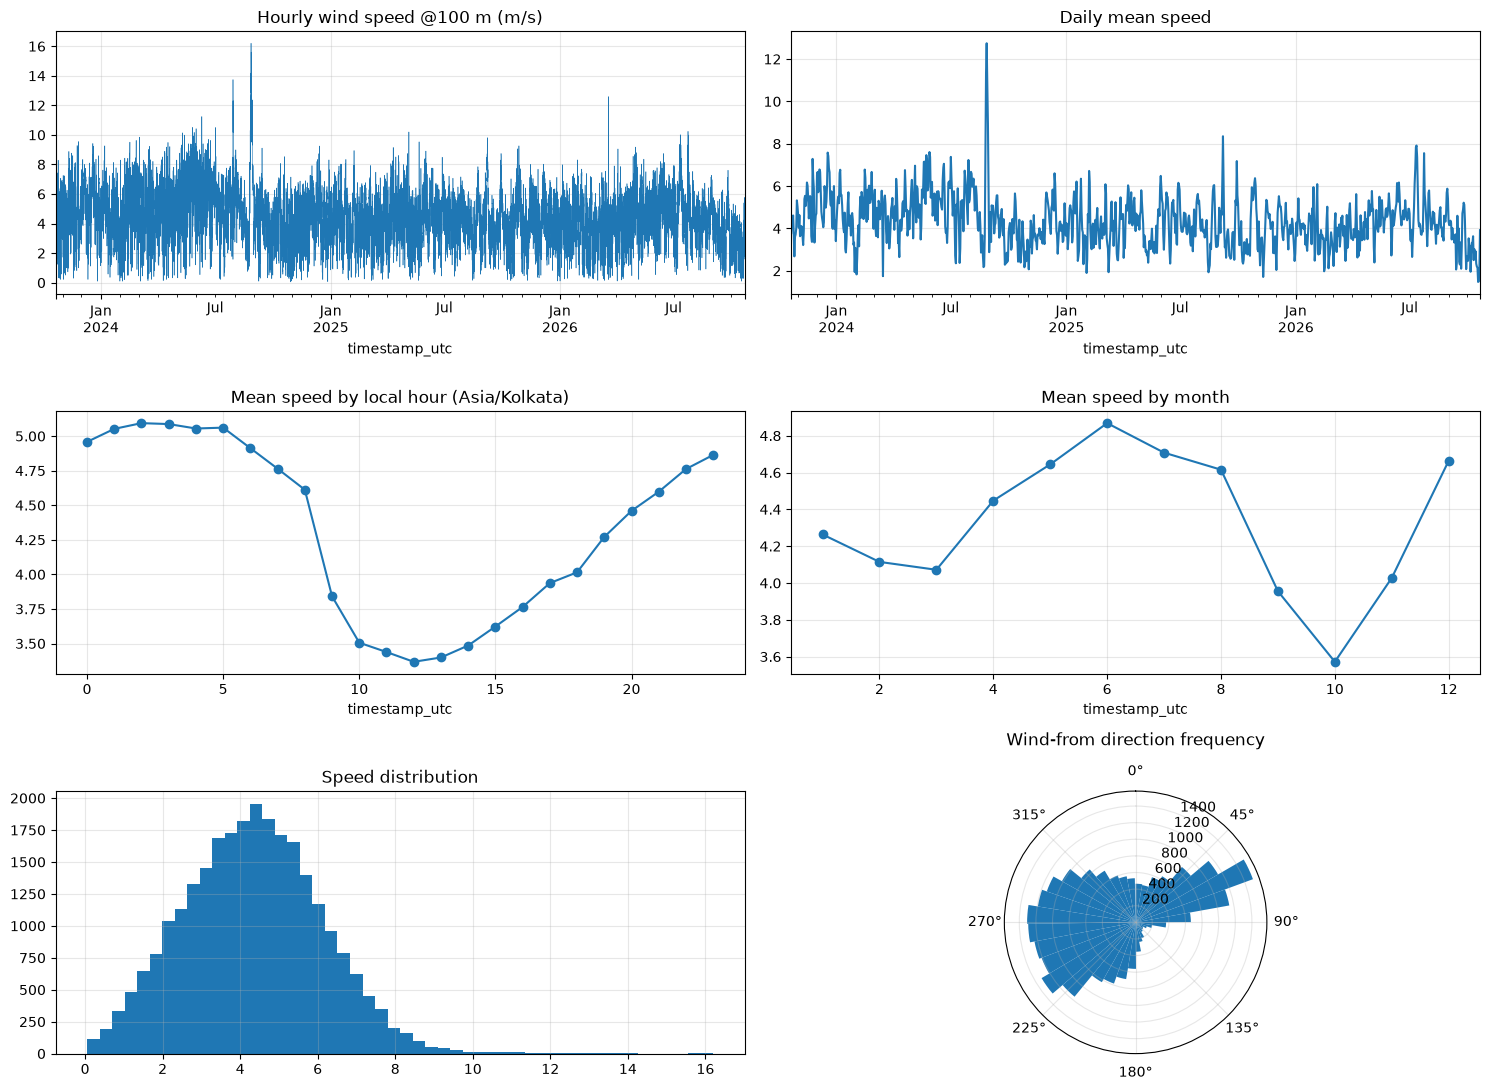

,ACF of speed
lag_h,
1,0.883727
3,0.658208
6,0.403773
12,0.191305
24,0.600359
48,0.443067
168,0.259898


Dominant periods (h) from spectrum: [np.float64(23.9), np.float64(24.0), np.float64(431.6)]


In [8]:
local = data.index.tz_localize("UTC").tz_convert(LOCAL_TZ)
fig, ax = plt.subplots(3, 2, figsize=(15, 11))
data.ws.plot(ax=ax[0, 0], lw=0.4, title="Hourly wind speed @100 m (m/s)")
data.ws.resample("D").mean().plot(ax=ax[0, 1], title="Daily mean speed")
data.groupby(local.hour).ws.mean().plot(ax=ax[1, 0], marker="o", title=f"Mean speed by local hour ({LOCAL_TZ})")
data.groupby(local.month).ws.mean().plot(ax=ax[1, 1], marker="o", title="Mean speed by month")
ax[2, 0].hist(data.ws.dropna(), bins=50); ax[2, 0].set_title("Speed distribution")
ax[2, 1].remove(); axp = fig.add_subplot(3, 2, 6, projection="polar")
d = data.dropna(subset=["wind_direction_deg"]); axp.set_theta_zero_location("N"); axp.set_theta_direction(-1)
axp.hist(np.deg2rad(d.wind_direction_deg), bins=36); axp.set_title("Wind-from direction frequency", pad=14)
plt.tight_layout(); plt.show()

# Autocorrelation at candidate seasonal periods (informs the SARIMAX period search)
x = data.ws.interpolate().to_numpy(); x = x - x.mean()
acf = lambda k: float(np.dot(x[:-k], x[k:]) / np.dot(x, x))
acf_tbl = pd.Series({k: acf(k) for k in [1, 3, 6, 12, 24, 48, 168]}, name="ACF of speed")
acf_tbl.index.name = "lag_h"; display(acf_tbl.to_frame())
spec = np.abs(np.fft.rfft(x)) ** 2; fr = np.fft.rfftfreq(len(x), 1)
top = np.argsort(spec[1:])[::-1][:6] + 1
print("Dominant periods (h) from spectrum:", sorted({round(1 / fr[i], 1) for i in top if 1 / fr[i] < 24 * 30}))

## 7. Feature engineering
Every feature in row *t* uses only observations at or before *t* (lags, trailing rolling windows). Direction enters as sine/cosine; clock features are cyclic. A leakage test below recomputes features from truncated data and demands identical values.

In [9]:
LAGS = [0, 1, 3, 6, 12, 24]
def build_features(d):
    f = pd.DataFrame(index=d.index)
    for L in LAGS:
        f[f"ws_lag{L}"] = d.ws.shift(L); f[f"sin_lag{L}"] = d.dir_sin.shift(L); f[f"cos_lag{L}"] = d.dir_cos.shift(L)
    for w in [3, 6, 12, 24]:
        f[f"ws_mean{w}"] = d.ws.rolling(w, min_periods=max(2, w // 2)).mean()
        f[f"ws_std{w}"] = d.ws.rolling(w, min_periods=max(2, w // 2)).std()
    for w in [6, 24]:
        f[f"sin_mean{w}"] = d.dir_sin.rolling(w, min_periods=w // 2).mean()
        f[f"cos_mean{w}"] = d.dir_cos.rolling(w, min_periods=w // 2).mean()
    f["dir_steadiness24"] = np.hypot(f.sin_mean24, f.cos_mean24)           # mean resultant length: 1 = steady direction
    f["ws_delta1"] = d.ws - d.ws.shift(1); f["ws_delta3"] = d.ws - d.ws.shift(3)
    f["ws_max24"] = d.ws.rolling(24, min_periods=12).max()
    # cyclic clock features (local time of the forecast origin)
    loc = d.index.tz_localize("UTC").tz_convert(LOCAL_TZ)
    hr = loc.hour + loc.minute / 60; doy = loc.dayofyear
    f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24)
    f["doy_sin"], f["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    # other observed weather (history only)
    f["ws10"] = d.ws10; f["ws_ratio_100_10"] = d.ws / d.ws10.clip(lower=0.5)
    f["temp"] = d.temp; f["temp_d24"] = d.temp - d.temp.shift(24)
    f["pres"] = d.pres; f["pres_d3"] = d.pres - d.pres.shift(3); f["pres_d24"] = d.pres - d.pres.shift(24)
    f["rh"] = d.rh; f["cloud"] = d.cloud
    return f

FEATS = build_features(data)
FEATURE_COLS = list(FEATS.columns)

# Leakage test: features at t from data truncated at t must equal features from the full series.
rng = np.random.default_rng(RANDOM_SEED)
for t in rng.choice(np.arange(300, N - 50), 8, replace=False):
    trunc = build_features(data.iloc[: t + 1]).iloc[-1]
    assert np.allclose(trunc.values.astype(float), FEATS.iloc[t].values.astype(float), equal_nan=True), f"Look-ahead in features at {t}"
print(f"{len(FEATURE_COLS)} features; leakage test passed on 8 random timestamps.")

47 features; leakage test passed on 8 random timestamps.


## 8. Chronological splits and the forecast-origin set
`train | validation | test` in time order. Validation is used only for tuning; the test block is scored once, by rolling forecasts from many origins. An origin at time *t* may use data up to *t*; its 24 targets are *t+1..t+24*. All models are scored on the **same** origins.

In [10]:
test_start = N - TEST_DAYS * 24
val_start = test_start - VAL_DAYS * 24
print("train      :", data.index[0], "->", data.index[val_start - 1], f"({val_start} h)")
print("validation :", data.index[val_start], "->", data.index[test_start - 1], f"({VAL_DAYS} d)")
print("test       :", data.index[test_start], "->", data.index[-1], f"({TEST_DAYS} d)")

def future_matrix(a):            # [t, h-1] = a[t+h]
    M = np.full((N, H), np.nan)
    for h in range(1, H + 1): M[: N - h, h - 1] = a[h:]
    return M
def seasonal_matrix(a):          # [t, h-1] = a[t+h-24]  (always <= t, so known at the origin)
    M = np.full((N, H), np.nan)
    for h in range(1, H + 1):
        k = 24 - h
        if k < N: M[k:, h - 1] = a[: N - k]
    return M

ws_a, sn_a, cs_a = data.ws.to_numpy(), data.dir_sin.to_numpy(), data.dir_cos.to_numpy()
Y = {"ws": future_matrix(ws_a), "sin": future_matrix(sn_a), "cos": future_matrix(cs_a)}
S = {"ws": seasonal_matrix(ws_a), "sin": seasonal_matrix(sn_a), "cos": seasonal_matrix(cs_a)}
ok = (~np.isnan(Y["ws"]).any(1) & ~np.isnan(Y["sin"]).any(1) & ~np.isnan(Y["cos"]).any(1)
      & ~np.isnan(S["ws"]).any(1) & ~np.isnan(S["sin"]).any(1)
      & ~np.isnan(ws_a) & ~np.isnan(sn_a) & ~np.isnan(cs_a))

def origin_set(lo, hi):           # origins with positions in [lo, hi], aligned to a fixed grid
    pos = np.arange(lo, hi + 1)
    pos = pos[(pos - lo) % ORIGIN_STEP_H == 0]
    return pos[ok[pos]]
VAL_ORIGINS  = origin_set(val_start, test_start - 1 - H)      # targets stay inside validation
TEST_ORIGINS = origin_set(test_start, N - 1 - H)
print(f"validation origins: {len(VAL_ORIGINS)} | test origins: {len(TEST_ORIGINS)}")

train      : 2023-10-21 00:00:00 -> 2026-02-23 23:00:00 (20568 h)
validation : 2026-02-24 00:00:00 -> 2026-05-24 23:00:00 (90 d)
test       : 2026-05-25 00:00:00 -> 2026-10-21 23:00:00 (150 d)
validation origins: 356 | test origins: 596


### Evaluation helpers
Speed: MAE and RMSE (m/s). Direction: **circular** absolute error in degrees (359 deg vs 1 deg = 2 deg), reported overall and for hours where the *observed* speed >= `DIR_MIN_SPEED`. Results are broken down by lead time.

In [11]:
def circ_err(pred_deg, true_deg):
    return np.abs((pred_deg - true_deg + 180) % 360 - 180)
def to_deg(s, c):
    return (np.rad2deg(np.arctan2(s, c)) + 360) % 360
def mean_res_len(s, c):
    return np.hypot(s, c)

def score(pred, origins):
    """pred = dict(ws, sin, cos) arrays (len(origins), H). Returns per-lead metrics DataFrame (index lead 1..H)."""
    yt = {k: Y[k][origins] for k in Y}
    e = pred["ws"] - yt["ws"]
    d_err = circ_err(to_deg(pred["sin"], pred["cos"]), to_deg(yt["sin"], yt["cos"]))
    fast = yt["ws"] >= DIR_MIN_SPEED
    out = pd.DataFrame({
        "speed_MAE": np.abs(e).mean(0), "speed_RMSE": np.sqrt((e ** 2).mean(0)),
        "dir_CMAE_all": d_err.mean(0),
        "dir_CMAE_fast": [d_err[fast[:, h], h].mean() if fast[:, h].any() else np.nan for h in range(H)],
    }, index=pd.RangeIndex(1, H + 1, name="lead_h"))
    return out

def summarize(results, origins, title):
    rows = []
    for name, pred in results.items():
        s = score(pred, origins)
        row = {"model": name}
        for L in LEADS_REPORTED:
            row[f"MAE@{L}h"] = s.speed_MAE[L]
        for L in LEADS_REPORTED:
            row[f"RMSE@{L}h"] = s.speed_RMSE[L]
        row["MAE_1-24h"], row["RMSE_1-24h"] = s.speed_MAE.mean(), s.speed_RMSE.mean()
        for L in LEADS_REPORTED:
            row[f"dirMAE_fast@{L}h"] = s.dir_CMAE_fast[L]
        row["dirMAE_all_1-24h"], row["dirMAE_fast_1-24h"] = s.dir_CMAE_all.mean(), s.dir_CMAE_fast.mean()
        rows.append(row)
    tbl = pd.DataFrame(rows).set_index("model")
    print(title); display(tbl.round(3)); return tbl
print("helpers ready")

helpers ready


## 9. Persistence baseline (Phase 2)
Every lead time repeats the latest observation (speed and the unit direction vector).

In [12]:
def persistence(origins):
    return {"ws": np.repeat(ws_a[origins][:, None], H, 1),
            "sin": np.repeat(sn_a[origins][:, None], H, 1), "cos": np.repeat(cs_a[origins][:, None], H, 1)}
val_res, test_res = {}, {}
val_res["Persistence"], test_res["Persistence"] = persistence(VAL_ORIGINS), persistence(TEST_ORIGINS)
_ = summarize({"Persistence": test_res["Persistence"]}, TEST_ORIGINS, "Persistence on test origins")

Persistence on test origins


,MAE@1h,MAE@6h,MAE@12h,MAE@24h,RMSE@1h,RMSE@6h,RMSE@12h,RMSE@24h,MAE_1-24h,RMSE_1-24h,dirMAE_fast@1h,dirMAE_fast@6h,dirMAE_fast@12h,dirMAE_fast@24h,dirMAE_all_1-24h,dirMAE_fast_1-24h
model,,,,,,,,,,,,,,,,
Persistence,0.558,1.241,1.242,1.041,0.841,1.565,1.582,1.398,1.184,1.52,10.418,29.349,32.479,24.574,32.751,27.964


## 10. Seasonal-naive baseline (Phase 2)
The value for hour *t+h* is the observation 24 h earlier (*t+h-24*, always already known at the origin).

In [13]:
def seasonal_naive(origins):
    return {k: S[k][origins].copy() for k in ["ws", "sin", "cos"]}
val_res["Seasonal naive (24h)"], test_res["Seasonal naive (24h)"] = seasonal_naive(VAL_ORIGINS), seasonal_naive(TEST_ORIGINS)
base_tbl = summarize({k: test_res[k] for k in ["Persistence", "Seasonal naive (24h)"]}, TEST_ORIGINS,
                     "BASELINE METRICS TO BEAT (test origins)")

BASELINE METRICS TO BEAT (test origins)


,MAE@1h,MAE@6h,MAE@12h,MAE@24h,RMSE@1h,RMSE@6h,RMSE@12h,RMSE@24h,MAE_1-24h,RMSE_1-24h,dirMAE_fast@1h,dirMAE_fast@6h,dirMAE_fast@12h,dirMAE_fast@24h,dirMAE_all_1-24h,dirMAE_fast_1-24h
model,,,,,,,,,,,,,,,,
Persistence,0.558,1.241,1.242,1.041,0.841,1.565,1.582,1.398,1.184,1.520,10.418,29.349,32.479,24.574,32.751,27.964
Seasonal naive (24h),0.973,1.038,1.039,1.041,1.290,1.396,1.396,1.398,1.040,1.373,22.152,24.366,24.379,24.574,28.156,22.840


## 11. SARIMAX (Phase 3)
* The original SARIMAX (`(1,0,1)x(1,0,1,24)`) stays in the candidate grid.
* Candidate seasonal periods: none, 12 h, 24 h (autocorrelation/spectrum in section 6 shows whether 168 h has any signal; a 168-h state space is too large for per-origin refiltering and weather has no weekly cycle).
* **Tuning** uses a fit window that ends before the validation block and is scored on validation origins only.
* **No leakage:** parameters are estimated once on data ending before the scored block; at each origin the model is *filtered* (`apply`, no refit) over only the trailing `SARIMAX_FILTER_DAYS` of observations up to that origin, then forecasts 24 h. Speed, sin and cos each get their own SARIMAX with the same orders.

In [14]:
SARIMAX_GRID = {
    "(1,0,1) none":            ((1, 0, 1), (0, 0, 0, 0)),
    "(2,0,1) none":            ((2, 0, 1), (0, 0, 0, 0)),
    "(1,0,0)x(1,0,0,12)":      ((1, 0, 0), (1, 0, 0, 12)),
    "(1,0,1)x(1,0,0,12)":      ((1, 0, 1), (1, 0, 0, 12)),
    "(1,0,0)x(1,0,0,24)":      ((1, 0, 0), (1, 0, 0, 24)),
    "(2,0,1)x(1,0,0,24)":      ((2, 0, 1), (1, 0, 0, 24)),
    "(1,0,1)x(1,0,0,24)":      ((1, 0, 1), (1, 0, 0, 24)),
    "(1,0,1)x(1,0,1,24) [orig]": ((1, 0, 1), (1, 0, 1, 24)),
}
W = SARIMAX_FILTER_DAYS * 24

def sarimax_fit(series, cfg):
    order, seas = cfg
    m = SARIMAX(series, order=order, seasonal_order=seas, trend="c", enforce_stationarity=False, enforce_invertibility=False)
    return m.fit(disp=False, maxiter=80)

def sarimax_roll(fitted, arr, origins):
    out = np.empty((len(origins), H))
    for i, o in enumerate(origins):
        seg = arr[max(0, o - W + 1): o + 1]
        out[i] = fitted.apply(seg, refit=False).forecast(H)
    return out

def sarimax_predict(cfg, fit_end, origins, targets=("ws", "sin", "cos")):
    arrs = {"ws": ws_a, "sin": sn_a, "cos": cs_a}
    out = {}
    for k in targets:
        fit_seg = arrs[k][max(0, fit_end - SARIMAX_FIT_DAYS * 24): fit_end]
        fitted = sarimax_fit(pd.Series(fit_seg).interpolate(limit_direction="both").to_numpy(), cfg)
        out[k] = sarimax_roll(fitted, arrs[k], origins)
    if "ws" in out: out["ws"] = np.clip(out["ws"], 0, None)
    if "sin" in out: out["sin"], out["cos"] = np.clip(out["sin"], -1, 1), np.clip(out["cos"], -1, 1)
    return out

# ---- tuning on validation (parameters fitted on data ending at val_start) ----
t0 = time.time(); tune_rows = []; sar_val_preds = {}
for name, cfg in SARIMAX_GRID.items():
    p = sarimax_predict(cfg, val_start, VAL_ORIGINS)
    s = score(p, VAL_ORIGINS); sar_val_preds[name] = p
    tune_rows.append({"config": name, "val_speed_RMSE": s.speed_RMSE.mean(), "val_speed_MAE": s.speed_MAE.mean(),
                      "val_dir_CMAE_fast": s.dir_CMAE_fast.mean()})
sar_tune = pd.DataFrame(tune_rows).set_index("config")
display(sar_tune.round(3))
best_sar_speed = sar_tune.val_speed_RMSE.idxmin(); best_sar_dir = sar_tune.val_dir_CMAE_fast.idxmin()
print(f"Best SARIMAX on validation -> speed: {best_sar_speed} | direction: {best_sar_dir}  ({time.time()-t0:.0f}s)")
val_res["SARIMAX"] = {"ws": sar_val_preds[best_sar_speed]["ws"], "sin": sar_val_preds[best_sar_dir]["sin"],
                      "cos": sar_val_preds[best_sar_dir]["cos"]}

,val_speed_RMSE,val_speed_MAE,val_dir_CMAE_fast
config,,,
"(1,0,1) none",1.543,1.249,49.041
"(2,0,1) none",1.530,1.238,47.507
"(1,0,0)x(1,0,0,12)",1.550,1.256,40.083
"(1,0,1)x(1,0,0,12)",1.536,1.243,49.154
"(1,0,0)x(1,0,0,24)",1.359,1.076,35.038
"(2,0,1)x(1,0,0,24)",1.355,1.074,40.077
"(1,0,1)x(1,0,0,24)",1.355,1.074,42.716
"(1,0,1)x(1,0,1,24) [orig]",1.307,1.017,31.453


Best SARIMAX on validation -> speed: (1,0,1)x(1,0,1,24) [orig] | direction: (1,0,1)x(1,0,1,24) [orig]  (153s)


In [15]:
# ---- held-out SARIMAX backtest: parameters fitted on data ending at test_start only ----
t0 = time.time()
sp = sarimax_predict(SARIMAX_GRID[best_sar_speed], test_start, TEST_ORIGINS, targets=("ws",))
dp = sarimax_predict(SARIMAX_GRID[best_sar_dir], test_start, TEST_ORIGINS, targets=("sin", "cos"))
test_res["SARIMAX"] = {"ws": sp["ws"], "sin": dp["sin"], "cos": dp["cos"]}
print(f"SARIMAX test backtest finished in {time.time()-t0:.0f}s over {len(TEST_ORIGINS)} origins")
_ = summarize({k: test_res[k] for k in ["Persistence", "Seasonal naive (24h)", "SARIMAX"]}, TEST_ORIGINS, "SARIMAX benchmark vs baselines (test)")

SARIMAX test backtest finished in 48s over 596 origins
SARIMAX benchmark vs baselines (test)


,MAE@1h,MAE@6h,MAE@12h,MAE@24h,RMSE@1h,RMSE@6h,RMSE@12h,RMSE@24h,MAE_1-24h,RMSE_1-24h,dirMAE_fast@1h,dirMAE_fast@6h,dirMAE_fast@12h,dirMAE_fast@24h,dirMAE_all_1-24h,dirMAE_fast_1-24h
model,,,,,,,,,,,,,,,,
Persistence,0.558,1.241,1.242,1.041,0.841,1.565,1.582,1.398,1.184,1.520,10.418,29.349,32.479,24.574,32.751,27.964
Seasonal naive (24h),0.973,1.038,1.039,1.041,1.290,1.396,1.396,1.398,1.040,1.373,22.152,24.366,24.379,24.574,28.156,22.840
SARIMAX,0.570,1.012,1.049,1.079,0.835,1.287,1.353,1.385,0.994,1.290,10.225,29.414,35.531,46.561,36.882,33.970


## 12. Nonlinear ML: gradient-boosted trees, direct multi-step (Phase 4)
**Strategy:** *direct* forecasting - a separate model per lead *h* = 1..24 and per target (speed, sin, cos) = 72 models. Features at the origin, target = value at *t+h*. No recursive feedback, so errors do not compound.

**No future data:** for a model trained with knowledge up to cutoff *c*, only rows with origin + h <= c are used (the target must already be observed). In the backtest the model is retrained on an expanding window every `REFIT_DAYS` and applied only to origins after its cutoff. Speed can be modelled as the change from the current speed ("delta") or as a level; both are tuned on validation. Direction is predicted as sin and cos, then recombined.

In [16]:
Xall = FEATS.to_numpy(dtype=float)

def make_gbm(p):
    if GBM_BACKEND == "lightgbm":
        return lgb.LGBMRegressor(n_estimators=p["n"], learning_rate=p["lr"], num_leaves=p["leaves"], min_child_samples=p["mcs"],
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                 random_state=RANDOM_SEED, verbose=-1, n_jobs=-1)
    if GBM_BACKEND == "xgboost":
        return xgb.XGBRegressor(n_estimators=p["n"], learning_rate=p["lr"], max_depth=max(2, int(np.log2(p["leaves"]))),
                                subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_SEED, n_jobs=-1)
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(max_iter=p["n"], learning_rate=p["lr"], max_leaf_nodes=p["leaves"], random_state=RANDOM_SEED)

def fit_gbm_set(cutoff, targets, p, speed_delta):
    """Train direct models using only information available at position `cutoff` (inclusive)."""
    models = {}
    for k in targets:
        arr = {"ws": ws_a, "sin": sn_a, "cos": cs_a}[k]
        for h in range(1, H + 1):
            rows = np.arange(0, cutoff - h + 1)                    # origin + h <= cutoff  -> target already observed
            y = arr[rows + h]
            if k == "ws" and speed_delta: y = y - ws_a[rows]
            good = ~np.isnan(y) & ~np.isnan(ws_a[rows])
            m = make_gbm(p); m.fit(Xall[rows[good]], y[good]); models[(k, h)] = m
    return models

def predict_gbm_set(models, origins, targets, speed_delta):
    out = {}
    for k in targets:
        P = np.column_stack([models[(k, h)].predict(Xall[origins]) for h in range(1, H + 1)])
        if k == "ws":
            if speed_delta: P = P + ws_a[origins][:, None]
            P = np.clip(P, 0, None)
        else: P = np.clip(P, -1, 1)
        out[k] = P
    return out

GBM_GRID = {"small":  dict(n=200, lr=0.05, leaves=7,  mcs=100),
            "medium": dict(n=250, lr=0.04, leaves=15, mcs=60),
            "large":  dict(n=300, lr=0.03, leaves=31, mcs=40)}

t0 = time.time(); gbm_rows = []; gbm_val = {}
for gname, p in GBM_GRID.items():
    for delta in (False, True):
        pr = predict_gbm_set(fit_gbm_set(val_start - 1, ["ws"], p, delta), VAL_ORIGINS, ["ws"], delta)
        gbm_val[("ws", gname, delta)] = pr["ws"]
        e = pr["ws"] - Y["ws"][VAL_ORIGINS]
        gbm_rows.append({"target": "speed", "config": gname, "speed_delta": delta, "val_RMSE": np.sqrt((e ** 2).mean()), "val_MAE": np.abs(e).mean()})
    pr = predict_gbm_set(fit_gbm_set(val_start - 1, ["sin", "cos"], p, False), VAL_ORIGINS, ["sin", "cos"], False)
    gbm_val[("dir", gname)] = pr
    yt = {k: Y[k][VAL_ORIGINS] for k in ["ws", "sin", "cos"]}
    err = circ_err(to_deg(pr["sin"], pr["cos"]), to_deg(yt["sin"], yt["cos"])); fast = yt["ws"] >= DIR_MIN_SPEED
    gbm_rows.append({"target": "direction", "config": gname, "speed_delta": np.nan, "val_RMSE": np.nan, "val_MAE": err[fast].mean()})
gbm_tune = pd.DataFrame(gbm_rows); display(gbm_tune.round(3))
bs = gbm_tune[gbm_tune.target == "speed"].sort_values("val_RMSE").iloc[0]
bd = gbm_tune[gbm_tune.target == "direction"].sort_values("val_MAE").iloc[0]
GBM_SPEED_CFG, GBM_SPEED_DELTA, GBM_DIR_CFG = bs.config, bool(bs.speed_delta), bd.config
print(f"Chosen on validation -> speed: {GBM_SPEED_CFG} (delta={GBM_SPEED_DELTA}) | direction: {GBM_DIR_CFG}  ({time.time()-t0:.0f}s)")
val_res["LightGBM" if GBM_BACKEND == "lightgbm" else GBM_BACKEND] = {
    "ws": gbm_val[("ws", GBM_SPEED_CFG, GBM_SPEED_DELTA)], **gbm_val[("dir", GBM_DIR_CFG)]}
ML_NAME = list(val_res.keys())[-1]

,target,config,speed_delta,val_RMSE,val_MAE
0,speed,small,False,1.270,0.969
1,speed,small,True,1.286,0.982
2,direction,small,NaN,NaN,24.383
3,speed,medium,False,1.258,0.956
4,speed,medium,True,1.266,0.961
5,direction,medium,NaN,NaN,24.074
6,speed,large,False,1.260,0.955
7,speed,large,True,1.264,0.959
8,direction,large,NaN,NaN,24.180


Chosen on validation -> speed: medium (delta=False) | direction: medium  (163s)


## 13. Rolling backtest (Phase 5)
For each 30-day block of the test period: retrain on everything observed up to the block's first origin, then forecast 24 h from every origin in the block. Every model is scored on the identical origins and the identical realised values.

In [17]:
t0 = time.time()
blocks = []; b = TEST_ORIGINS[0]
while b <= TEST_ORIGINS[-1]:
    blocks.append((b, b + REFIT_DAYS * 24)); b += REFIT_DAYS * 24
parts_ws, parts_dir, refit_log = [], [], []
for lo, hi in blocks:
    idx = np.where((TEST_ORIGINS >= lo) & (TEST_ORIGINS < hi))[0]
    if len(idx) == 0: continue
    cut = int(TEST_ORIGINS[idx[0]])
    m_ws = fit_gbm_set(cut, ["ws"], GBM_GRID[GBM_SPEED_CFG], GBM_SPEED_DELTA)
    m_dir = fit_gbm_set(cut, ["sin", "cos"], GBM_GRID[GBM_DIR_CFG], False)
    parts_ws.append((idx, predict_gbm_set(m_ws, TEST_ORIGINS[idx], ["ws"], GBM_SPEED_DELTA)["ws"]))
    parts_dir.append((idx, predict_gbm_set(m_dir, TEST_ORIGINS[idx], ["sin", "cos"], False)))
    refit_log.append({"trained_through": str(data.index[cut]), "n_origins_scored": len(idx)})
gp = {"ws": np.zeros((len(TEST_ORIGINS), H)), "sin": np.zeros((len(TEST_ORIGINS), H)), "cos": np.zeros((len(TEST_ORIGINS), H))}
for idx, p in parts_ws: gp["ws"][idx] = p
for idx, p in parts_dir:
    gp["sin"][idx], gp["cos"][idx] = p["sin"], p["cos"]
test_res[ML_NAME] = gp
display(pd.DataFrame(refit_log))
print(f"Backtest finished in {time.time()-t0:.0f}s | models: {list(test_res)} | origins: {len(TEST_ORIGINS)}")

,trained_through,n_origins_scored
0,2026-05-25 00:00:00,120
1,2026-06-24 00:00:00,120
2,2026-07-24 00:00:00,120
3,2026-08-23 00:00:00,120
4,2026-09-22 00:00:00,116


Backtest finished in 194s | models: ['Persistence', 'Seasonal naive (24h)', 'SARIMAX', 'LightGBM'] | origins: 596


## 14. Model comparison: tables and error by lead time

HELD-OUT ROLLING BACKTEST (test block)


,MAE@1h,MAE@6h,MAE@12h,MAE@24h,RMSE@1h,RMSE@6h,RMSE@12h,RMSE@24h,MAE_1-24h,RMSE_1-24h,dirMAE_fast@1h,dirMAE_fast@6h,dirMAE_fast@12h,dirMAE_fast@24h,dirMAE_all_1-24h,dirMAE_fast_1-24h
model,,,,,,,,,,,,,,,,
Persistence,0.558,1.241,1.242,1.041,0.841,1.565,1.582,1.398,1.184,1.520,10.418,29.349,32.479,24.574,32.751,27.964
Seasonal naive (24h),0.973,1.038,1.039,1.041,1.290,1.396,1.396,1.398,1.040,1.373,22.152,24.366,24.379,24.574,28.156,22.840
SARIMAX,0.570,1.012,1.049,1.079,0.835,1.287,1.353,1.385,0.994,1.290,10.225,29.414,35.531,46.561,36.882,33.970
LightGBM,0.510,0.905,0.897,0.931,0.727,1.190,1.173,1.209,0.885,1.143,8.917,20.477,21.589,24.322,25.426,20.448


Validation block (used for tuning only)


,MAE@1h,MAE@6h,MAE@12h,MAE@24h,RMSE@1h,RMSE@6h,RMSE@12h,RMSE@24h,MAE_1-24h,RMSE_1-24h,dirMAE_fast@1h,dirMAE_fast@6h,dirMAE_fast@12h,dirMAE_fast@24h,dirMAE_all_1-24h,dirMAE_fast_1-24h
model,,,,,,,,,,,,,,,,
Persistence,0.502,1.779,2.056,1.178,0.695,2.141,2.491,1.561,1.613,1.992,10.173,31.801,35.464,30.543,35.829,31.748
Seasonal naive (24h),1.270,1.180,1.180,1.178,1.721,1.562,1.561,1.561,1.236,1.619,29.310,30.705,30.623,30.543,35.070,29.827
SARIMAX,0.493,1.037,1.048,1.017,0.699,1.312,1.353,1.313,1.017,1.307,9.434,29.142,34.185,41.549,35.495,31.453
LightGBM,0.477,0.976,0.981,1.002,0.726,1.233,1.249,1.282,0.956,1.251,8.973,22.956,26.290,27.663,28.506,24.069


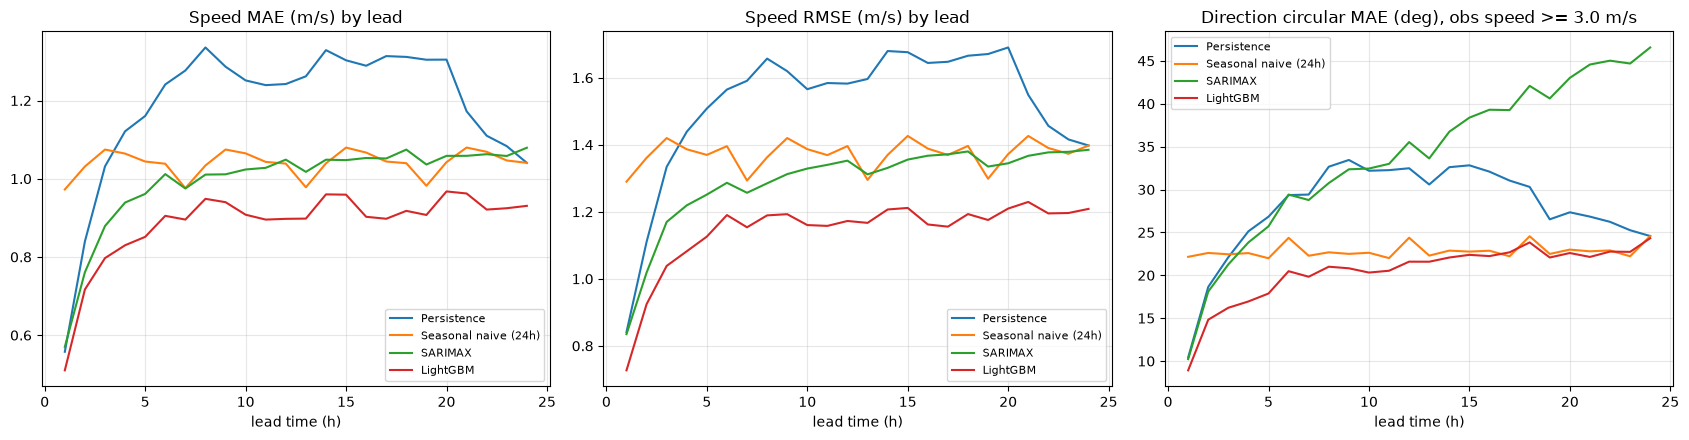

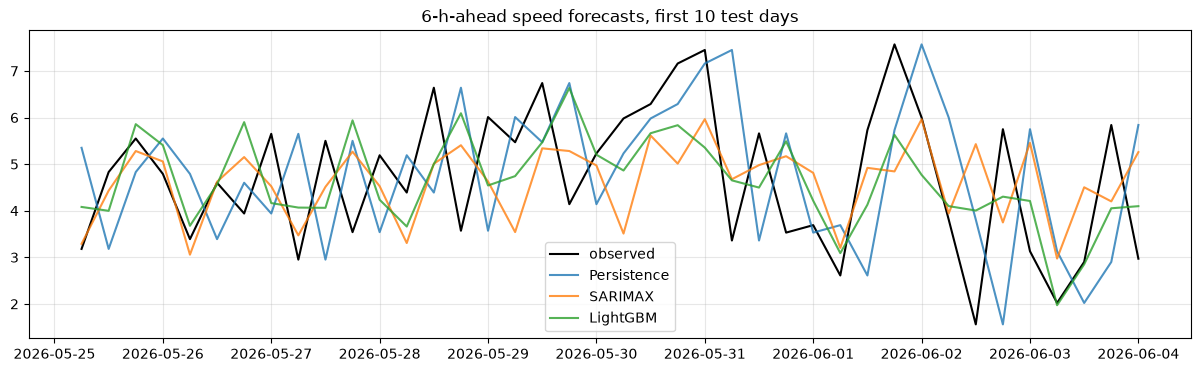

In [18]:
test_tbl = summarize(test_res, TEST_ORIGINS, "HELD-OUT ROLLING BACKTEST (test block)")
val_tbl = summarize(val_res, VAL_ORIGINS, "Validation block (used for tuning only)")
by_lead = {m: score(p, TEST_ORIGINS) for m, p in test_res.items()}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for m, s in by_lead.items():
    ax[0].plot(s.index, s.speed_MAE, label=m); ax[1].plot(s.index, s.speed_RMSE, label=m); ax[2].plot(s.index, s.dir_CMAE_fast, label=m)
ax[0].set_title("Speed MAE (m/s) by lead"); ax[1].set_title("Speed RMSE (m/s) by lead")
ax[2].set_title(f"Direction circular MAE (deg), obs speed >= {DIR_MIN_SPEED} m/s")
for a in ax: a.set_xlabel("lead time (h)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

lead_tbl = pd.concat({m: s.loc[LEADS_REPORTED] for m, s in by_lead.items()}, names=["model"])
lead_tbl.round(3).to_csv(os.path.join(OUT_DIR, "backtest_metrics_by_lead.csv"))
test_tbl.round(4).to_csv(os.path.join(OUT_DIR, "backtest_summary.csv"))

# visual spot check: one multi-day slice of 6 h-ahead forecasts vs observation
o6 = TEST_ORIGINS
fig, ax = plt.subplots(figsize=(15, 4))
sl = slice(0, 40)
tt = data.index[o6[sl] + 6]
ax.plot(tt, Y["ws"][o6[sl], 5], "k", label="observed")
for m in ["Persistence", "SARIMAX", ML_NAME]: ax.plot(tt, test_res[m]["ws"][sl, 5], label=m, alpha=0.8)
ax.set_title("6-h-ahead speed forecasts, first 10 test days"); ax.legend(); plt.show()

## 15. Final model selection (Phase 7)
Models are chosen on **held-out rolling-backtest** results (hyperparameters were already fixed on validation). Speed winner = lowest RMSE averaged over leads 1-24 h; direction winner = lowest circular MAE (observed speed >= threshold) averaged over leads 1-24 h. A paired block bootstrap over origins (blocks of 4 origins = 1 day, to respect autocorrelation) tests whether the winner beats the best simple baseline.

In [19]:
def per_origin_err(pred, kind):
    if kind == "speed":
        return np.abs(pred["ws"] - Y["ws"][TEST_ORIGINS]).mean(1)
    e = circ_err(to_deg(pred["sin"], pred["cos"]), to_deg(Y["sin"][TEST_ORIGINS], Y["cos"][TEST_ORIGINS]))
    fast = Y["ws"][TEST_ORIGINS] >= DIR_MIN_SPEED
    return np.where(fast.sum(1) > 0, (e * fast).sum(1) / np.maximum(fast.sum(1), 1), np.nan)

def block_boot_ci(diff, block=4, nboot=2000, seed=RANDOM_SEED):
    diff = diff[~np.isnan(diff)]; rng = np.random.default_rng(seed)
    nb = int(np.ceil(len(diff) / block)); starts = np.arange(0, len(diff) - block + 1)
    means = [np.concatenate([diff[s:s + block] for s in rng.choice(starts, nb)])[:len(diff)].mean() for _ in range(nboot)]
    return np.percentile(means, [2.5, 97.5])

baselines = ["Persistence", "Seasonal naive (24h)"]
sel_rows = []
for kind, col in [("speed", "RMSE_1-24h"), ("direction", "dirMAE_fast_1-24h")]:
    ranked = test_tbl[col].sort_values()
    winner = ranked.index[0]
    best_base = min(baselines, key=lambda m: test_tbl.loc[m, col])
    diff = per_origin_err(test_res[winner], "speed" if kind == "speed" else "dir") - per_origin_err(test_res[best_base], "speed" if kind == "speed" else "dir")
    lo, hi = block_boot_ci(diff)
    sel_rows.append({"target": kind, "metric": col, "winner": winner, "winner_score": ranked.iloc[0],
                     "best_baseline": best_base, "baseline_score": test_tbl.loc[best_base, col],
                     "improvement_%": 100 * (1 - ranked.iloc[0] / test_tbl.loc[best_base, col]),
                     "mean_err_diff_vs_baseline_95%CI": f"[{lo:+.3f}, {hi:+.3f}]", "significantly_better": bool(hi < 0)})
selection = pd.DataFrame(sel_rows).set_index("target"); display(selection.round(3))
SPEED_WINNER, DIR_WINNER = selection.loc["speed", "winner"], selection.loc["direction", "winner"]

# success criteria check
crit = []
for lead in LEADS_REPORTED:
    for kind, col in [("speed", f"MAE@{lead}h"), ("direction", f"dirMAE_fast@{lead}h")]:
        w = SPEED_WINNER if kind == "speed" else DIR_WINNER
        crit.append({"criterion": f"{kind} winner ({w}) beats both baselines at {lead} h", "met": bool(all(test_tbl.loc[w, col] < test_tbl.loc[b, col] for b in baselines))})
crit.append({"criterion": f"scored on many forecast origins (n={len(TEST_ORIGINS)} >= 100)", "met": len(TEST_ORIGINS) >= 100})
crit.append({"criterion": "direction error uses circular statistics", "met": True})
crit.append({"criterion": "ML predictions do not use the Forecast API", "met": True})
display(pd.DataFrame(crit))
ml_is_speed = SPEED_WINNER == ML_NAME; ml_is_dir = DIR_WINNER == ML_NAME
if not (ml_is_speed and ml_is_dir):
    print(f"NOTE: {ML_NAME} is not the winner for all targets (speed: {SPEED_WINNER}, direction: {DIR_WINNER}). "
          f"The engine below still uses {ML_NAME} alone as specified; see the report for the gap.")

,metric,winner,winner_score,best_baseline,baseline_score,improvement_%,mean_err_diff_vs_baseline_95%CI,significantly_better
target,,,,,,,,
speed,RMSE_1-24h,LightGBM,1.143,Seasonal naive (24h),1.373,16.775,"[-0.201, -0.108]",True
direction,dirMAE_fast_1-24h,LightGBM,20.448,Seasonal naive (24h),22.840,10.470,"[-4.683, -0.178]",True


,criterion,met
0,speed winner (LightGBM) beats both baselines a...,True
1,direction winner (LightGBM) beats both baselin...,True
2,speed winner (LightGBM) beats both baselines a...,True
3,direction winner (LightGBM) beats both baselin...,True
4,speed winner (LightGBM) beats both baselines a...,True
5,direction winner (LightGBM) beats both baselin...,True
6,speed winner (LightGBM) beats both baselines a...,True
7,direction winner (LightGBM) beats both baselin...,True
8,scored on many forecast origins (n=596 >= 100),True
9,direction error uses circular statistics,True


In [20]:
tbl_txt = "```" + chr(10) + test_tbl.round(3).to_string() + chr(10) + "```"
report_md = f"""# Model-selection report
Site {LATITUDE:.4f}, {LONGITUDE:.4f} | data {data.index[0]} to {data.index[-1]} UTC ({N} hourly rows, wind @{WIND_VAR_HEIGHT_M} m)
Tuning (validation): {VAL_DAYS} days. Held-out rolling backtest: {TEST_DAYS} days, {len(TEST_ORIGINS)} forecast origins every {ORIGIN_STEP_H} h, leads 1-{H} h, ML retrained every {REFIT_DAYS} days.

## Winners
- Speed: **{SPEED_WINNER}** (mean RMSE 1-24 h {selection.loc['speed','winner_score']:.3f} m/s vs {selection.loc['speed','best_baseline']} {selection.loc['speed','baseline_score']:.3f}; {selection.loc['speed','improvement_%']:.1f}% better; 95% CI of error difference {selection.loc['speed','mean_err_diff_vs_baseline_95%CI']}).
- Direction: **{DIR_WINNER}** (circular MAE, obs speed >= {DIR_MIN_SPEED} m/s, {selection.loc['direction','winner_score']:.1f} deg vs {selection.loc['direction','best_baseline']} {selection.loc['direction','baseline_score']:.1f} deg; {selection.loc['direction','improvement_%']:.1f}% better; CI {selection.loc['direction','mean_err_diff_vs_baseline_95%CI']}).
- SARIMAX settings chosen on validation: speed {best_sar_speed}; direction {best_sar_dir}.
- {ML_NAME} settings chosen on validation: speed {GBM_SPEED_CFG} (delta target={GBM_SPEED_DELTA}); direction {GBM_DIR_CFG}.

## Held-out metrics
{tbl_txt}

Metrics are computed against ERA5-type reanalysis values, not site anemometer data.
"""
open(os.path.join(OUT_DIR, "model_selection_report.md"), "w", encoding="utf-8").write(report_md)
display(Markdown(report_md))

# Model-selection report
Site 23.0225, 72.5714 | data 2023-10-21 00:00:00 to 2026-10-21 23:00:00 UTC (26328 hourly rows, wind @100 m)
Tuning (validation): 90 days. Held-out rolling backtest: 150 days, 596 forecast origins every 6 h, leads 1-24 h, ML retrained every 30 days.

## Winners
- Speed: **LightGBM** (mean RMSE 1-24 h 1.143 m/s vs Seasonal naive (24h) 1.373; 16.8% better; 95% CI of error difference [-0.201, -0.108]).
- Direction: **LightGBM** (circular MAE, obs speed >= 3.0 m/s, 20.4 deg vs Seasonal naive (24h) 22.8 deg; 10.5% better; CI [-4.683, -0.178]).
- SARIMAX settings chosen on validation: speed (1,0,1)x(1,0,1,24) [orig]; direction (1,0,1)x(1,0,1,24) [orig].
- LightGBM settings chosen on validation: speed medium (delta target=False); direction medium.

## Held-out metrics
```
                      MAE@1h  MAE@6h  MAE@12h  MAE@24h  RMSE@1h  RMSE@6h  RMSE@12h  RMSE@24h  MAE_1-24h  RMSE_1-24h  dirMAE_fast@1h  dirMAE_fast@6h  dirMAE_fast@12h  dirMAE_fast@24h  dirMAE_all_1-24h  dirMAE_fast_1-24h
model                                                                                                                                                                                                                     
Persistence            0.558   1.241    1.242    1.041    0.841    1.565     1.582     1.398      1.184       1.520          10.418          29.349           32.479           24.574            32.751             27.964
Seasonal naive (24h)   0.973   1.038    1.039    1.041    1.290    1.396     1.396     1.398      1.040       1.373          22.152          24.366           24.379           24.574            28.156             22.840
SARIMAX                0.570   1.012    1.049    1.079    0.835    1.287     1.353     1.385      0.994       1.290          10.225          29.414           35.531           46.561            36.882             33.970
LightGBM               0.510   0.905    0.897    0.931    0.727    1.190     1.173     1.209      0.885       1.143           8.917          20.477           21.589           24.322            25.426             20.448
```

Metrics are computed against ERA5-type reanalysis values, not site anemometer data.


## 16. Model-only 24-hour prediction (Phase 8)
Final ML models are retrained on **all** cleaned history (every target observed by the last timestamp), then predict the 24 h after the final observation. No Forecast API value is read anywhere in this section.

Origin (last observation): 2026-10-21 23:00:00 UTC | trained on 26328 rows (36s) | model: LightGBM


,timestamp_local,lead_h,pred_speed_100m_ms,pred_direction_deg,direction_confidence
timestamp_utc,,,,,
2026-10-22 00:00:00,2026-10-22 05:30,1,5.217,58.180,0.996
2026-10-22 01:00:00,2026-10-22 06:30,2,5.307,61.213,1.006
2026-10-22 02:00:00,2026-10-22 07:30,3,5.289,64.239,0.998
2026-10-22 03:00:00,2026-10-22 08:30,4,5.332,64.855,1.018
2026-10-22 04:00:00,2026-10-22 09:30,5,3.834,67.322,1.010
2026-10-22 05:00:00,2026-10-22 10:30,6,3.209,68.815,0.988
2026-10-22 06:00:00,2026-10-22 11:30,7,2.982,69.882,0.972
2026-10-22 07:00:00,2026-10-22 12:30,8,2.886,70.653,0.934
2026-10-22 08:00:00,2026-10-22 13:30,9,3.009,68.345,0.927


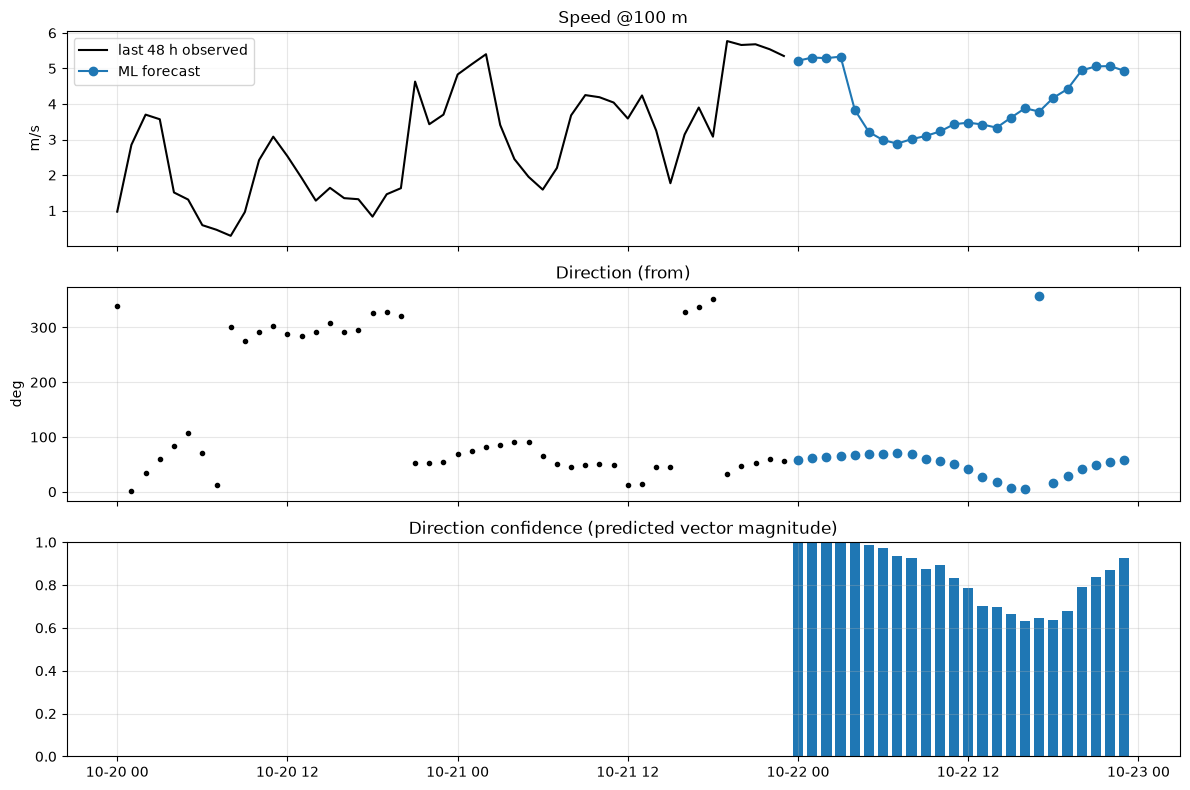

In [21]:
LAST = int(np.where(~np.isnan(ws_a) & ~np.isnan(sn_a))[0][-1])       # last origin with a valid observation
t0 = time.time()
fm_ws = fit_gbm_set(LAST, ["ws"], GBM_GRID[GBM_SPEED_CFG], GBM_SPEED_DELTA)
fm_dir = fit_gbm_set(LAST, ["sin", "cos"], GBM_GRID[GBM_DIR_CFG], False)
fc_ws = predict_gbm_set(fm_ws, np.array([LAST]), ["ws"], GBM_SPEED_DELTA)["ws"][0]
fc_dir = predict_gbm_set(fm_dir, np.array([LAST]), ["sin", "cos"], False)
fut_idx = pd.date_range(data.index[LAST] + pd.Timedelta(hours=1), periods=H, freq="h", name="timestamp_utc")
model_forecast = pd.DataFrame({
    "pred_speed_100m_ms": fc_ws,
    "pred_direction_deg": to_deg(fc_dir["sin"][0], fc_dir["cos"][0]),
    "direction_confidence": mean_res_len(fc_dir["sin"][0], fc_dir["cos"][0]),
}, index=fut_idx)
model_forecast.insert(0, "timestamp_local", fut_idx.tz_localize("UTC").tz_convert(LOCAL_TZ).strftime("%Y-%m-%d %H:%M"))
model_forecast.insert(1, "lead_h", np.arange(1, H + 1))
print(f"Origin (last observation): {data.index[LAST]} UTC | trained on {LAST+1} rows ({time.time()-t0:.0f}s) | model: {ML_NAME}")
display(model_forecast.round(3))
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
hist = data.iloc[LAST - 47: LAST + 1]
ax[0].plot(hist.index, hist.ws, "k", label="last 48 h observed"); ax[0].plot(fut_idx, model_forecast.pred_speed_100m_ms, "o-", label="ML forecast")
ax[0].set_ylabel("m/s"); ax[0].legend(); ax[0].set_title("Speed @100 m")
ax[1].plot(hist.index, hist.wind_direction_deg, "k."); ax[1].plot(fut_idx, model_forecast.pred_direction_deg, "o"); ax[1].set_ylabel("deg"); ax[1].set_title("Direction (from)")
ax[2].bar(fut_idx, model_forecast.direction_confidence, width=0.03); ax[2].set_ylim(0, 1); ax[2].set_title("Direction confidence (predicted vector magnitude)")
plt.tight_layout(); plt.show()

## 17. Direction confidence and yaw recommendations (Phase 6)
The ML model predicts sine and cosine separately; the direction is `atan2(sin, cos)`. The **vector magnitude** `R = sqrt(sin^2+cos^2)` is a confidence proxy: when the two components are small or cancel, the direction is ill-defined (R near 0). Below, R and observed wind speed are related to realised circular error on the held-out backtest, and a reliability threshold is chosen on the *validation* block.

Direction reliability threshold R >= 0.75 (selected on validation); speed threshold 3.0 m/s


,R_threshold,coverage_%,circ_MAE_kept_deg
0,0.1,99.9,25.4
1,0.2,99.3,25.1
2,0.3,98.0,24.6
3,0.4,95.9,23.8
4,0.5,92.6,22.6
5,0.6,88.2,21.3
6,0.7,81.9,20.0
7,0.8,69.1,18.3
8,0.9,38.2,15.3


,count,mean,median
predicted R,,,
"(-0.001, 0.2]",98,70.4,60.0
"(0.2, 0.4]",494,62.9,51.7
"(0.4, 0.6]",1100,52.0,40.5
"(0.6, 0.8]",2723,32.1,24.0
"(0.8, 1.0]",9564,18.5,12.8


,count,mean,median
observed speed (m/s),,,
"(-0.001, 2.0]",1263,57.5,45.0
"(2.0, 3.0]",1797,34.0,22.6
"(3.0, 5.0]",7366,21.8,14.8
"(5.0, 8.0]",3674,18.2,13.1
"(8.0, 100.0]",204,12.5,8.7


,circular MAE (deg)
all hours,25.4
obs speed >= 3.0 m/s,20.5
R >= 0.75,19.3
both,17.3


Corr(R, error): -0.46 (negative = higher confidence -> smaller error)


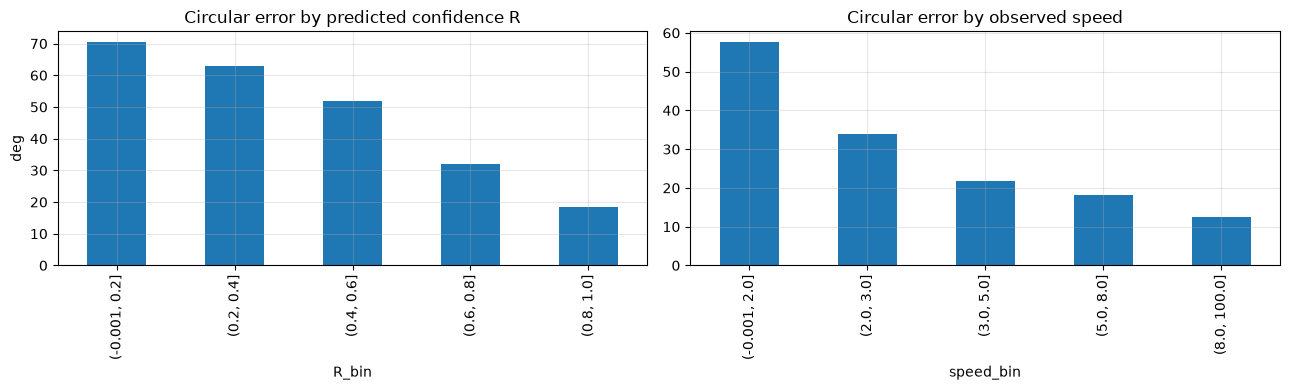

In [22]:
ml_t, ml_v = test_res[ML_NAME], val_res[ML_NAME]
def flat(pred, origins):
    yt = {k: Y[k][origins] for k in Y}
    return pd.DataFrame({"lead_h": np.tile(np.arange(1, H + 1), len(origins)),
                         "R": mean_res_len(pred["sin"], pred["cos"]).ravel(),
                         "err": circ_err(to_deg(pred["sin"], pred["cos"]), to_deg(yt["sin"], yt["cos"])).ravel(),
                         "obs_speed": yt["ws"].ravel(), "pred_speed": pred["ws"].ravel()})
dt, dv = flat(ml_t, TEST_ORIGINS), flat(ml_v, VAL_ORIGINS)

# threshold on validation: smallest R giving retained error <= 80% of overall error with >= 50% coverage
cands = np.round(np.arange(0.1, 0.95, 0.05), 2); CONF_MIN = 0.5
for c in cands:
    kept = dv[dv.R >= c]
    if len(kept) / len(dv) >= 0.5 and kept.err.mean() <= 0.8 * dv.err.mean():
        CONF_MIN = float(c); break
print(f"Direction reliability threshold R >= {CONF_MIN} (selected on validation); speed threshold {DIR_MIN_SPEED} m/s")

sweep = pd.DataFrame([{"R_threshold": c, "coverage_%": 100 * (dt.R >= c).mean(), "circ_MAE_kept_deg": dt[dt.R >= c].err.mean()} for c in cands[::2]])
display(sweep.round(1))
dt["R_bin"] = pd.cut(dt.R, [0, 0.2, 0.4, 0.6, 0.8, 1.0001], include_lowest=True)
dt["speed_bin"] = pd.cut(dt.obs_speed, [0, 2, DIR_MIN_SPEED, 5, 8, 100], include_lowest=True)
display(dt.groupby("R_bin", observed=True).err.agg(["count", "mean", "median"]).round(1).rename_axis("predicted R"))
display(dt.groupby("speed_bin", observed=True).err.agg(["count", "mean", "median"]).round(1).rename_axis("observed speed (m/s)"))
fast = dt.obs_speed >= DIR_MIN_SPEED
summary_dir = pd.Series({"all hours": dt.err.mean(), f"obs speed >= {DIR_MIN_SPEED} m/s": dt[fast].err.mean(),
                         f"R >= {CONF_MIN}": dt[dt.R >= CONF_MIN].err.mean(),
                         f"both": dt[fast & (dt.R >= CONF_MIN)].err.mean()}, name="circular MAE (deg)")
display(summary_dir.round(1).to_frame())
print("Corr(R, error):", round(dt.R.corr(dt.err), 3), "(negative = higher confidence -> smaller error)")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dt.groupby("R_bin", observed=True).err.mean().plot.bar(ax=ax[0], title="Circular error by predicted confidence R"); ax[0].set_ylabel("deg")
dt.groupby("speed_bin", observed=True).err.mean().plot.bar(ax=ax[1], title="Circular error by observed speed"); plt.tight_layout(); plt.show()

In [23]:
def signed_angle_difference(target_deg, current_deg):
    return (target_deg - current_deg + 180) % 360 - 180

def yaw_plan(fc, current_heading, deadband, conf_min, speed_min):
    """Advisory heading: follow predicted wind-from direction only when it is reliable; otherwise hold. Deadband avoids hunting."""
    cmd, rows = current_heading, []
    for ts, r in fc.iterrows():
        reliable = (r.direction_confidence >= conf_min) and (r.pred_speed_100m_ms >= speed_min)
        note = "hold: low confidence or below cut-in/low-speed" if not reliable else "track predicted wind direction"
        if reliable:
            if cmd is None or abs(signed_angle_difference(r.pred_direction_deg, cmd)) > deadband:
                cmd = float(r.pred_direction_deg)
            else: note = "hold: within deadband"
        rows.append({"direction_reliable": bool(reliable), "recommended_nacelle_heading_deg": cmd, "yaw_note": note})
    return pd.DataFrame(rows, index=fc.index)

# cut-in is known after turbine loading; use DIR_MIN_SPEED here as the generic usability limit
yaw = yaw_plan(model_forecast, CURRENT_NACELLE_HEADING_DEG, YAW_DEADBAND_DEG, CONF_MIN, DIR_MIN_SPEED)
yaw["yaw_change_vs_prev_hour_deg"] = yaw.recommended_nacelle_heading_deg.diff().map(lambda v: np.nan if pd.isna(v) else (v + 180) % 360 - 180)
if CURRENT_NACELLE_HEADING_DEG is not None:
    yaw["yaw_change_from_current_deg"] = [signed_angle_difference(h, CURRENT_NACELLE_HEADING_DEG) if pd.notna(h) else np.nan for h in yaw.recommended_nacelle_heading_deg]
display(pd.concat([model_forecast[["pred_speed_100m_ms", "pred_direction_deg", "direction_confidence"]], yaw], axis=1).round(2))
print(f"{int(yaw.direction_reliable.sum())}/{H} hours have reliable direction. Conventional upwind HAWT: heading = wind-from direction. Advisory only.")

,pred_speed_100m_ms,pred_direction_deg,direction_confidence,direction_reliable,recommended_nacelle_heading_deg,yaw_note,yaw_change_vs_prev_hour_deg
timestamp_utc,,,,,,,
2026-10-22 00:00:00,5.22,58.18,1.00,True,58.18,track predicted wind direction,NaN
2026-10-22 01:00:00,5.31,61.21,1.01,True,58.18,hold: within deadband,0.00
2026-10-22 02:00:00,5.29,64.24,1.00,True,58.18,hold: within deadband,0.00
2026-10-22 03:00:00,5.33,64.85,1.02,True,58.18,hold: within deadband,0.00
2026-10-22 04:00:00,3.83,67.32,1.01,True,67.32,track predicted wind direction,9.14
2026-10-22 05:00:00,3.21,68.81,0.99,True,67.32,hold: within deadband,0.00
2026-10-22 06:00:00,2.98,69.88,0.97,False,67.32,hold: low confidence or below cut-in/low-speed,0.00
2026-10-22 07:00:00,2.89,70.65,0.93,False,67.32,hold: low confidence or below cut-in/low-speed,0.00
2026-10-22 08:00:00,3.01,68.34,0.93,True,67.32,hold: within deadband,0.00


15/24 hours have reliable direction. Conventional upwind HAWT: heading = wind-from direction. Advisory only.


## 18. NREL turbine power-curve loading
Loaded from the installed `turbine-models` package (NREL). The curve is verified before use: strictly increasing wind speeds, non-negative power, peak equal to the spec's rated power, zero power outside cut-in/cut-out, and hub height versus the data height.

turbine-models 0.2.2 | available onshore models: 27


,verified
wind speeds strictly increasing,True
power non-negative,True
peak power == spec rated power,True
starts at zero power,True
hub height known,True


{'name': '2023NREL_Bespoke_3.3MW_148', 'package_version': '0.2.2', 'rated_kw': 3300.0, 'cut_in_ms': 3.25, 'cut_out_ms': 25.0, 'hub_height_m': 100, 'rotor_diameter_m': 148, 'curve_type': 'theoretical', 'origin': 'reference model'}


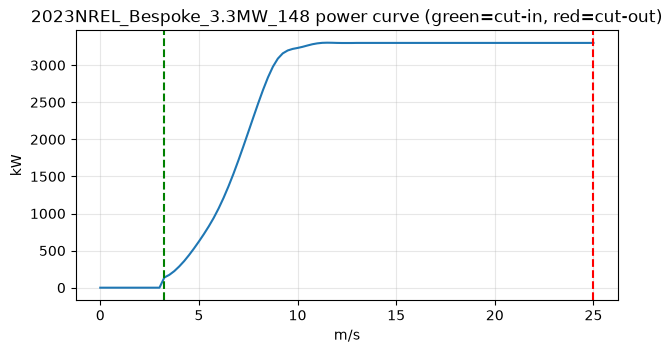

Hub 100 m vs data 100 m -> shear correction not applied


In [24]:
import yaml, turbine_models
from turbine_models.parser import Turbines
T = Turbines()
print("turbine-models", turbine_models.__version__, "| available onshore models:", len(T.turbines(TURBINE_GROUP)))
curve_df = T.table(TURBINE_NAME, TURBINE_GROUP)[["wind_speed_ms", "power_kw"]].dropna().sort_values("wind_speed_ms").reset_index(drop=True)
spec_file = os.path.join(os.path.dirname(turbine_models.__file__), "specs", TURBINE_GROUP.capitalize(), f"{TURBINE_NAME}.yaml")
spec = yaml.safe_load(open(spec_file))

nz = curve_df[curve_df.power_kw > 0]
cut_in = spec.get("cut_in_wind_speed") or float(nz.wind_speed_ms.iloc[0])
cut_out = spec.get("cut_out_wind_speed") or float(nz.wind_speed_ms.iloc[-1])
rated_kw = spec.get("rated_power") or float(curve_df.power_kw.max())
hub = spec.get("hub_height")
checks = {
    "wind speeds strictly increasing": bool((np.diff(curve_df.wind_speed_ms) > 0).all()),
    "power non-negative": bool((curve_df.power_kw >= 0).all()),
    "peak power == spec rated power": bool(np.isclose(curve_df.power_kw.max(), rated_kw, rtol=0.01)),
    "starts at zero power": bool(curve_df.power_kw.iloc[0] == 0),
    "hub height known": hub is not None,
}
display(pd.Series(checks, name="verified").to_frame())
assert all(checks.values()), "Turbine curve failed verification; choose another TURBINE_NAME"
TURBINE = {"name": TURBINE_NAME, "package_version": turbine_models.__version__, "rated_kw": float(rated_kw), "cut_in_ms": float(cut_in),
           "cut_out_ms": float(cut_out), "hub_height_m": hub, "rotor_diameter_m": spec.get("rotor_diameter"),
           "curve_type": spec.get("power_curve_type"), "origin": spec.get("origin")}
print(TURBINE)
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(curve_df.wind_speed_ms, curve_df.power_kw); ax.axvline(cut_in, ls="--", c="g"); ax.axvline(cut_out, ls="--", c="r")
ax.set_xlabel("m/s"); ax.set_ylabel("kW"); ax.set_title(f"{TURBINE_NAME} power curve (green=cut-in, red=cut-out)"); plt.show()

# wind-shear adjustment only if hub height differs from the 100 m data height
SHEAR_ALPHA = SHEAR_ALPHA_OVERRIDE if SHEAR_ALPHA_OVERRIDE is not None else alpha_est
def to_hub_speed(v100):
    if abs(float(hub) - WIND_VAR_HEIGHT_M) <= 5: return np.asarray(v100, float)
    return np.asarray(v100, float) * (float(hub) / WIND_VAR_HEIGHT_M) ** SHEAR_ALPHA
print(f"Hub {hub} m vs data {WIND_VAR_HEIGHT_M} m -> shear correction {'not applied' if abs(float(hub)-WIND_VAR_HEIGHT_M)<=5 else f'applied (alpha={SHEAR_ALPHA:.2f})'}")

def power_kw(v):
    v = np.asarray(v, float)
    p = np.interp(v, curve_df.wind_speed_ms, curve_df.power_kw)
    return np.where((v < cut_in) | (v >= cut_out), 0.0, p)

## 19. Hourly power and energy estimation
Hourly mean power (kW) x 1 h = kWh. Idealised: no wakes, availability, curtailment, icing, electrical losses or air-density correction. **Observed generation is not available for this site**, so energy accuracy against actual output cannot be measured. As a clearly-labelled *proxy*, the backtest compares curve-energy from predicted wind with curve-energy from the reanalysis wind (this isolates wind-forecast error only).

In [25]:
energy = model_forecast[["pred_speed_100m_ms"]].copy()
energy["pred_speed_hub_ms"] = to_hub_speed(energy.pred_speed_100m_ms)
energy["power_kw"] = power_kw(energy.pred_speed_hub_ms)
energy["energy_kwh"] = energy.power_kw * 1.0
TOTAL_KWH = float(energy.energy_kwh.sum())
cf = TOTAL_KWH / (TURBINE["rated_kw"] * H)
print(f"Expected energy next {H} h: {TOTAL_KWH:,.0f} kWh | capacity factor {100*cf:.1f}% | peak {energy.power_kw.max():,.0f} kW")
display(energy.round(2))

# proxy energy error on the held-out backtest (kWh per hour, vs curve applied to reanalysis wind)
rows = []
for m, p in test_res.items():
    e = power_kw(to_hub_speed(p["ws"])) - power_kw(to_hub_speed(Y["ws"][TEST_ORIGINS]))
    for L in LEADS_REPORTED: rows.append({"model": m, "lead_h": L, "energy_MAE_kWh": np.abs(e[:, L-1]).mean(), "energy_RMSE_kWh": np.sqrt((e[:, L-1]**2).mean())})
    rows.append({"model": m, "lead_h": "24h total", "energy_MAE_kWh": np.abs(e.sum(1)).mean(), "energy_RMSE_kWh": np.sqrt((e.sum(1)**2).mean())})
energy_proxy = pd.DataFrame(rows); display(energy_proxy.pivot(index="model", columns="lead_h", values="energy_MAE_kWh").round(1).rename_axis(columns="MAE kWh (proxy)"))
energy_proxy.to_csv(os.path.join(OUT_DIR, "energy_proxy_backtest.csv"), index=False)

Expected energy next 24 h: 7,768 kWh | capacity factor 9.8% | peak 757 kW


,pred_speed_100m_ms,pred_speed_hub_ms,power_kw,energy_kwh
timestamp_utc,,,,
2026-10-22 00:00:00,5.22,5.22,708.87,708.87
2026-10-22 01:00:00,5.31,5.31,745.82,745.82
2026-10-22 02:00:00,5.29,5.29,738.51,738.51
2026-10-22 03:00:00,5.33,5.33,756.55,756.55
2026-10-22 04:00:00,3.83,3.83,244.26,244.26
2026-10-22 05:00:00,3.21,3.21,0.00,0.00
2026-10-22 06:00:00,2.98,2.98,0.00,0.00
2026-10-22 07:00:00,2.89,2.89,0.00,0.00
2026-10-22 08:00:00,3.01,3.01,0.00,0.00


MAE kWh (proxy),1,6,12,24,24h total
model,,,,,
LightGBM,152.6,283.6,277.5,288.2,3908.3
Persistence,174.7,387.8,379.5,318.4,6730.2
SARIMAX,181.1,320.4,331.7,338.6,5197.6
Seasonal naive (24h),283.2,319.9,319.4,318.4,4344.7


## 20. Optional Forecast API comparison (isolated; Previous Runs method)
Not used for training, features or the prediction above. **Why Previous Runs:** for past dates the regular Forecast API and the Historical Forecast API return values *identical* to the archive (their recent 100 m values are the same model analysis), so comparing against them measures nothing. The **Previous Runs API** stores the forecast that was actually issued the day before (`*_previous_day1`).

* **Part A (held-out block, lead 24 h):** for every test origin *o*, the model's 24-h-ahead forecast for hour *T = o+24* is compared with the API's previous-day forecast for the same hour *T* and with the observed value at *T* (matched UTC timestamps). Errors are always against observed values.
* **Part B (latest forecast):** the model-only 24 h forecast above vs observed vs API, for the same timestamps, where observations already exist.
* **Caveat:** "observed" is reanalysis from the same family of weather models as the API, which structurally favours the API. This is a benchmark against a professional service, not a measurement against a site sensor.

Part A: 596 matched hours of 596 test origins (2026-05-26 00:00:00 to 2026-10-21 18:00:00), lead 24 h, UTC timestamps matched by inner join


,hours,speed_MAE,speed_RMSE,dir_CMAE_all,dir_CMAE_fast
ML model (LightGBM),596.0,0.931,1.209,29.852,24.322
Forecast API (previous day),596.0,0.829,1.123,19.680,15.235
Persistence (reference),596.0,1.041,1.398,30.544,24.574


Speed |error| difference, model minus API: mean +0.102 m/s, 95% block-bootstrap CI [+0.025, +0.191] -> API closer


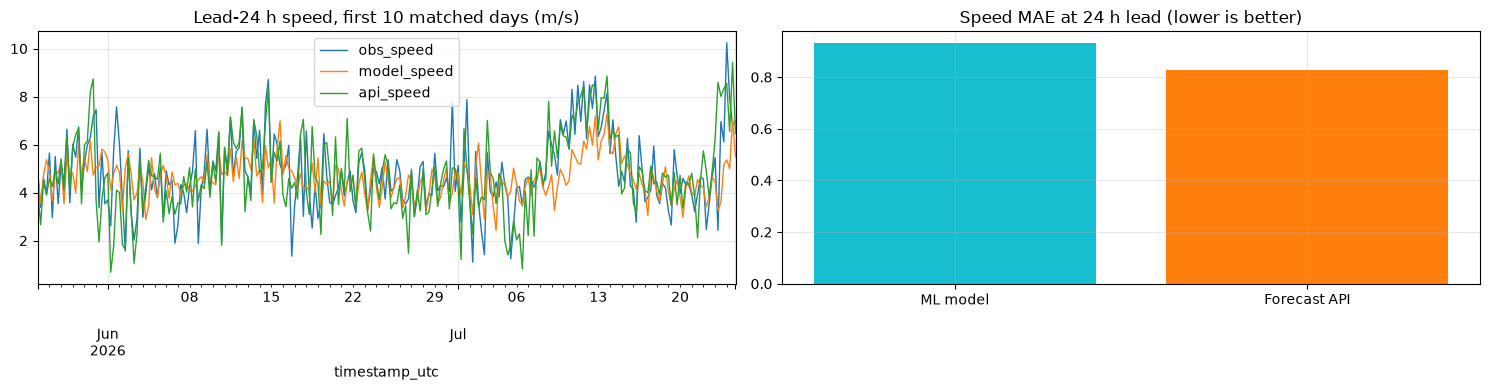

Part B: 24 of 24 forecast hours have API and observed values at matching timestamps


,hours,speed_MAE,speed_RMSE,dir_CMAE_all,dir_CMAE_fast
ML model,24.0,0.838,0.918,17.515,13.382
Forecast API (previous day),24.0,0.738,0.887,8.833,9.000


,pred_speed_100m_ms,pred_direction_deg,api_speed,api_dir,obs_speed,obs_dir
timestamp_utc,,,,,,
2026-10-22 00:00:00,5.22,58.18,5.39,73,5.66,62
2026-10-22 01:00:00,5.31,61.21,5.31,72,5.95,70
2026-10-22 02:00:00,5.29,64.24,5.77,71,6.52,79
2026-10-22 03:00:00,5.33,64.85,4.08,71,4.61,77
2026-10-22 04:00:00,3.83,67.32,3.83,78,4.27,74
2026-10-22 05:00:00,3.21,68.81,3.43,77,4.05,77
2026-10-22 06:00:00,2.98,69.88,3.05,80,3.60,76
2026-10-22 07:00:00,2.89,70.65,2.72,70,3.27,65
2026-10-22 08:00:00,3.01,68.34,2.73,50,3.69,50


Note: the model uses leads 1-24 h from its origin, the API forecast is the previous-day run (older information); Part A is the like-for-like lead-24 h comparison.


In [26]:
def fetch_previous_runs(lat, lon, start, end):
    r = requests.get("https://previous-runs-api.open-meteo.com/v1/forecast", params={
        "latitude": lat, "longitude": lon, "start_date": start, "end_date": end, "timezone": "UTC", "wind_speed_unit": "ms",
        "hourly": "wind_speed_100m_previous_day1,wind_direction_100m_previous_day1"}, timeout=120)
    r.raise_for_status(); h = r.json()["hourly"]
    return pd.DataFrame({"timestamp_utc": pd.to_datetime(h["time"]), "api_speed": h["wind_speed_100m_previous_day1"],
                         "api_dir": h["wind_direction_100m_previous_day1"]}).set_index("timestamp_utc")

def fetch_observed(lat, lon, start, end):
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": lat, "longitude": lon, "start_date": start, "end_date": end, "timezone": "UTC", "wind_speed_unit": "ms",
        "hourly": "wind_speed_100m,wind_direction_100m"}, timeout=120)
    r.raise_for_status(); h = r.json()["hourly"]
    return pd.DataFrame({"timestamp_utc": pd.to_datetime(h["time"]), "obs_speed": h["wind_speed_100m"],
                         "obs_dir": h["wind_direction_100m"]}).set_index("timestamp_utc")

def cmp_metrics(df, pred_s, pred_d):
    e = df[pred_s] - df.obs_speed; de = circ_err(df[pred_d], df.obs_dir); fast = df.obs_speed >= DIR_MIN_SPEED
    return {"hours": len(df), "speed_MAE": e.abs().mean(), "speed_RMSE": float(np.sqrt((e ** 2).mean())),
            "dir_CMAE_all": de.mean(), "dir_CMAE_fast": de[fast].mean()}

forecast_api_comparison = {}
try:
    # ---- Part A: held-out block, lead 24 h, matched timestamps --------------------------------
    tgt_pos = TEST_ORIGINS + 24
    tgt_ts = data.index[tgt_pos]
    api_all = fetch_previous_runs(LATITUDE, LONGITUDE, str(tgt_ts.min().date()), str(tgt_ts.max().date()))
    A = pd.DataFrame({"model_speed": test_res[ML_NAME]["ws"][:, 23], "model_dir": to_deg(test_res[ML_NAME]["sin"][:, 23], test_res[ML_NAME]["cos"][:, 23]),
                      "persist_speed": test_res["Persistence"]["ws"][:, 23], "persist_dir": to_deg(test_res["Persistence"]["sin"][:, 23], test_res["Persistence"]["cos"][:, 23]),
                      "obs_speed": Y["ws"][TEST_ORIGINS, 23], "obs_dir": to_deg(Y["sin"][TEST_ORIGINS, 23], Y["cos"][TEST_ORIGINS, 23])},
                     index=pd.DatetimeIndex(tgt_ts, name="timestamp_utc")).join(api_all, how="inner").dropna()
    print(f"Part A: {len(A)} matched hours of {len(TEST_ORIGINS)} test origins "
          f"({A.index.min()} to {A.index.max()}), lead 24 h, UTC timestamps matched by inner join")
    tblA = pd.DataFrame({"ML model (LightGBM)": cmp_metrics(A, "model_speed", "model_dir"),
                         "Forecast API (previous day)": cmp_metrics(A, "api_speed", "api_dir"),
                         "Persistence (reference)": cmp_metrics(A, "persist_speed", "persist_dir")}).T
    display(tblA.round(3))
    d_speed = (A.model_speed - A.obs_speed).abs().to_numpy() - (A.api_speed - A.obs_speed).abs().to_numpy()
    lo, hi = block_boot_ci(d_speed, block=4)
    verdict = "model closer" if hi < 0 else "API closer" if lo > 0 else "no significant difference"
    print(f"Speed |error| difference, model minus API: mean {d_speed.mean():+.3f} m/s, 95% block-bootstrap CI [{lo:+.3f}, {hi:+.3f}] -> {verdict}")
    forecast_api_comparison["part_a_lead24"] = {"matched_hours": int(len(A)), "table": json.loads(tblA.round(4).reset_index().to_json(orient="records")),
                                                "speed_abs_err_diff_model_minus_api_95CI": [float(lo), float(hi)], "verdict": verdict}
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    A[["obs_speed", "model_speed", "api_speed"]].iloc[:24 * 10].plot(ax=ax[0], lw=1, title="Lead-24 h speed, first 10 matched days (m/s)")
    names = ["ML model", "Forecast API"]; vals = [tblA.loc["ML model (LightGBM)", "speed_MAE"], tblA.loc["Forecast API (previous day)", "speed_MAE"]]
    ax[1].bar(names, vals, color=["tab:cyan", "tab:orange"]); ax[1].set_title("Speed MAE at 24 h lead (lower is better)")
    plt.tight_layout(); plt.show()

    # ---- Part B: latest model-only forecast vs observed vs API ----------------------------------
    b0, b1 = str(model_forecast.index.min().date()), str(model_forecast.index.max().date())
    B = model_forecast[["pred_speed_100m_ms", "pred_direction_deg"]].join(fetch_previous_runs(LATITUDE, LONGITUDE, b0, b1), how="inner")
    obs = fetch_observed(LATITUDE, LONGITUDE, b0, b1)
    B = B.join(obs, how="inner").dropna()
    print(f"Part B: {len(B)} of {H} forecast hours have API and observed values at matching timestamps")
    if len(B):
        tblB = pd.DataFrame({"ML model": cmp_metrics(B, "pred_speed_100m_ms", "pred_direction_deg"),
                             "Forecast API (previous day)": cmp_metrics(B, "api_speed", "api_dir")}).T
        display(tblB.round(3)); display(B.round(2))
        print("Note: the model uses leads 1-24 h from its origin, the API forecast is the previous-day run (older information); "
              "Part A is the like-for-like lead-24 h comparison.")
        forecast_api_comparison["part_b_latest"] = {"matched_hours": int(len(B)), "table": json.loads(tblB.round(4).reset_index().to_json(orient="records"))}
    else:
        print("Observations for these hours are not yet available in the archive: no accuracy claim is made for Part B.")
except Exception as exc:
    print("Forecast API comparison unavailable:", repr(exc), "- model forecast is unaffected.")

## 21. CSV / JSON export

In [27]:
final = pd.concat([model_forecast, yaw, energy[["pred_speed_hub_ms", "power_kw", "energy_kwh"]]], axis=1)
final.insert(0, "forecast_origin_utc", str(data.index[LAST]))
csv_path = os.path.join(OUT_DIR, "wind_24_hour_predictions.csv"); json_path = os.path.join(OUT_DIR, "wind_24_hour_predictions.json")
final.round(4).to_csv(csv_path)
meta = {
    "site": {"latitude": LATITUDE, "longitude": LONGITUDE, "grid_cell": {k: meta_api[k] for k in ["latitude", "longitude", "elevation"]}},
    "data": {"source": "Open-Meteo Historical Weather API (reanalysis)", "variable_height_m": WIND_VAR_HEIGHT_M, "rows": N,
             "start_utc": str(data.index[0]), "end_utc": str(data.index[-1]), "interpolated_hours": int(data.was_interpolated.sum()),
             "remaining_missing_hours": int(rem.sum()), "data_age_days": report["data_age_days"]},
    "model": {"name": ML_NAME, "backend": GBM_BACKEND, "strategy": "direct multi-step, 24 horizons x (speed, sin, cos)",
              "speed_config": {"name": GBM_SPEED_CFG, "delta_target": GBM_SPEED_DELTA, **GBM_GRID[GBM_SPEED_CFG]},
              "direction_config": {"name": GBM_DIR_CFG, **GBM_GRID[GBM_DIR_CFG]},
              "trained_through_utc": str(data.index[LAST]), "forecast_api_used_for_model_predictions": False},
    "selection": json.loads(selection.reset_index().to_json(orient="records")),
    "heldout_backtest": {"origins": int(len(TEST_ORIGINS)), "days": TEST_DAYS, "summary": json.loads(test_tbl.round(4).reset_index().to_json(orient="records"))},
    "direction_policy": {"min_confidence_R": CONF_MIN, "min_speed_ms": DIR_MIN_SPEED, "yaw_deadband_deg": YAW_DEADBAND_DEG,
                         "current_nacelle_heading_deg": CURRENT_NACELLE_HEADING_DEG},
    "turbine": TURBINE, "energy": {"total_kwh_24h": TOTAL_KWH, "capacity_factor": cf, "note": "idealised curve energy; no observed generation available"},
    "forecast_api_comparison": forecast_api_comparison,
    "safety_note": "Advisory predictions only; no turbine commands are issued.",
}
with open(json_path, "w", encoding="utf-8") as f:
    json.dump({"metadata": meta, "predictions": json.loads(final.reset_index().to_json(orient="records", date_format="iso"))}, f, indent=2, default=str)
print("Saved:", csv_path, "|", json_path); display(final.head(6).round(2))

Saved: outputs\wind_24_hour_predictions.csv | outputs\wind_24_hour_predictions.json


,forecast_origin_utc,timestamp_local,lead_h,pred_speed_100m_ms,pred_direction_deg,direction_confidence,direction_reliable,recommended_nacelle_heading_deg,yaw_note,yaw_change_vs_prev_hour_deg,pred_speed_hub_ms,power_kw,energy_kwh
timestamp_utc,,,,,,,,,,,,,
2026-10-22 00:00:00,2026-10-21 23:00:00,2026-10-22 05:30,1,5.22,58.18,1.00,True,58.18,track predicted wind direction,NaN,5.22,708.87,708.87
2026-10-22 01:00:00,2026-10-21 23:00:00,2026-10-22 06:30,2,5.31,61.21,1.01,True,58.18,hold: within deadband,0.00,5.31,745.82,745.82
2026-10-22 02:00:00,2026-10-21 23:00:00,2026-10-22 07:30,3,5.29,64.24,1.00,True,58.18,hold: within deadband,0.00,5.29,738.51,738.51
2026-10-22 03:00:00,2026-10-21 23:00:00,2026-10-22 08:30,4,5.33,64.85,1.02,True,58.18,hold: within deadband,0.00,5.33,756.55,756.55
2026-10-22 04:00:00,2026-10-21 23:00:00,2026-10-22 09:30,5,3.83,67.32,1.01,True,67.32,track predicted wind direction,9.14,3.83,244.26,244.26
2026-10-22 05:00:00,2026-10-21 23:00:00,2026-10-22 10:30,6,3.21,68.81,0.99,True,67.32,hold: within deadband,0.00,3.21,0.00,0.00


## 22. Assumptions and limitations
* **Data are reanalysis, not a site sensor.** Open-Meteo archive values (ERA5-family, ~9-25 km grid) at 100 m. All "errors" measure agreement with that dataset; real anemometer/SCADA validation is still required. The returned grid cell may be offset from the entered point (see section 5).
* **Height:** wind is at 100 m; the chosen turbine's hub height is compared and a power-law shear correction is applied only if they differ by more than 5 m.
* **Freshness:** the archive lags real time by several days, so "next 24 hours" means the 24 h after the last available observation, not necessarily after today. Operational use needs a near-real-time observation feed.
* **Gaps:** only gaps of up to 3 h are interpolated; longer gaps are excluded from training and scoring.
* **Backtest design:** the ML model is retrained every 30 days (not every origin); SARIMAX parameters are frozen at the test start and the model is re-filtered at each origin. Hyperparameters were tuned on the validation block only, but the final winner is read from a single test block, so seasonal coverage is limited (about 5 months).
* **Direction:** predicted from separately modelled sine/cosine, so the vector magnitude can be below 1; it is used as a confidence proxy, not a calibrated probability. Direction below `DIR_MIN_SPEED` or low confidence is not acted on.
* **Yaw:** advisory only; assumes an upwind horizontal-axis turbine whose heading convention matches meteorological wind-from degrees. No yaw-loss model, no controller limits, no commands are sent.
* **Energy:** curve-based (NREL `turbine-models`, theoretical curve) with no wake, availability, curtailment, turbulence, icing or air-density corrections. No observed generation exists here, so kWh accuracy against actual output is not measured; the backtest energy numbers are a wind-error proxy only.
* **Forecast API:** comparison only (Previous Runs API, matched by UTC timestamp, lead 24 h), never an input. "Observed" is reanalysis from the same weather-model family as the API, which favours the API; it is not a site-sensor measurement.
* **Not probabilistic:** no prediction intervals yet.